<a href="https://colab.research.google.com/github/ginaldoribeiro/ginaldoribeiro/blob/main/classificador_tumores_ISIC_(3).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🔬 Classificador Multimodal de Tumores — ISIC 2020
**Saída:** Benigno `(0)` | Maligno `(1)`

---
## 📋 Estrutura do Notebook
| # | Parte | Conteúdo |
|---|---|---|
| 1 | **Setup** | Ambiente, Drive, Imports, Configuração |
| 2 | **Carregamento** | Leitura do CSV |
| 3 | **🔍 Verificação de Qualidade** | Nulos, células vazias, duplicatas, heatmap |
| 4 | **⚖️ Análise de Balanceamento** | Distribuição, impacto, demo WeightedSampler |
| 5 | **🔧 Pré-processamento** | Tratamento, encoding, normalização, split, relatório |
| 6 | **🖼️ EDA Visual** | Amostras de imagens, estatísticas de pixels |
| 7 | **🧠 Arquiteturas** | EfficientNet-B0, ResNet-50, MobileNetV3-L, Tabular-MLP |
| 8 | **🏋️ Treinamento** | Validação de dados, loop corrigido (sem NaN) |
| 9 | **📈 Resultados** | ROC, Confusion Matrix, Radar, Comparação |

> ⚠️ **GPU recomendada:** *Editar → Configurações do notebook → GPU (T4)*

---
### 🐛 Bugs corrigidos nesta versão
| Bug | Descrição | Correção |
|---|---|---|
| ① | `_epoch_eval` chamava `model()` **2× por batch** | Logit calculado 1× e reutilizado |
| ② | NaN nas features tabulares propagava pela rede | `torch.nan_to_num()` em `tabs` e `logits` |
| ③ | `roc_auc_score` recebia `probs` com NaN → `ValueError` | `_safe_auc()` filtra NaN/Inf antes |


---
# ⚙️ PARTE 1 — Setup


## 1.1 – Verificação do Ambiente

In [1]:
!nvidia-smi 2>/dev/null || echo 'CPU mode'
import torch
print(f'PyTorch : {torch.__version__}')
print(f'CUDA    : {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU     : {torch.cuda.get_device_name(0)}')


Fri Jun  5 14:45:34 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 1.2 – Google Drive
> Faça upload do `dataset.zip` no Drive e ajuste `ZIP_PATH`.


In [2]:
from google.colab import drive
drive.mount('/content/drive')
ZIP_PATH = '/content/drive/MyDrive/dataset.zip'  # ← ajuste aqui
import os
print('✓ Encontrado' if os.path.exists(ZIP_PATH) else '✗ Não encontrado — verifique o caminho')


Mounted at /content/drive
✓ Encontrado


## 1.3 – Imports

In [3]:
import os, io, zipfile, random, warnings, time
from copy import deepcopy
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
%matplotlib inline
plt.rcParams['figure.dpi'] = 100
sns.set_style('whitegrid')

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    precision_score, recall_score, f1_score, confusion_matrix,
    balanced_accuracy_score, matthews_corrcoef, brier_score_loss,
    log_loss, roc_curve, precision_recall_curve,
)
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.models import efficientnet_b0, resnet50, mobilenet_v3_large
from PIL import Image
print('Imports OK ✓')


Imports OK ✓


## 1.4 – Configuração Central

In [4]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Dispositivo: {DEVICE}')

CFG = {
    'zip_path'   : ZIP_PATH,
    'output_dir' : '/content/saida_projeto',
    'img_size'   : 224,
    'epochs'     : 15,
    'batch_size' : 32,
    'lr'         : 1e-4,
    'weight_decay': 1e-5,
    'dropout'    : 0.4,
    'pos_weight' : 10.0,
    'seed'       : 42,
    'num_workers': 2,
    'test_size'  : 0.15,
    'val_size'   : 0.15,
    'threshold'  : 0.30,
}

def seed_all(s=CFG['seed']):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

seed_all()
os.makedirs(CFG['output_dir'], exist_ok=True)
print(f"Saídas em: {CFG['output_dir']}")


Dispositivo: cuda
Saídas em: /content/saida_projeto


---
# 📂 PARTE 2 — Carregamento dos Dados


In [5]:
def carregar_csv(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zf:
        with zf.open('data.csv') as f:
            return pd.read_csv(f)

df_raw = carregar_csv(CFG['zip_path'])  # mantém cópia bruta para comparação
df     = df_raw.copy()

print(f'Shape       : {df.shape[0]:,} linhas × {df.shape[1]} colunas')
print(f'\nColunas     : {list(df.columns)}')
print(f'\nPrimeiras linhas:')
df.head()


Shape       : 33,126 linhas × 8 colunas

Colunas     : ['image_name', 'patient_id', 'sex', 'age_approx', 'anatom_site_general_challenge', 'diagnosis', 'benign_malignant', 'target']

Primeiras linhas:


,image_name,patient_id,sex,age_approx,anatom_site_general_challenge,diagnosis,benign_malignant,target
0,ISIC_2637011,IP_7279968,male,45.0,head/neck,unknown,benign,0
1,ISIC_0015719,IP_3075186,female,45.0,upper extremity,unknown,benign,0
2,ISIC_0052212,IP_2842074,female,50.0,lower extremity,nevus,benign,0
3,ISIC_0068279,IP_6890425,female,45.0,head/neck,unknown,benign,0
4,ISIC_0074268,IP_8723313,female,55.0,upper extremity,unknown,benign,0


---
# 🔍 PARTE 3 — Verificação de Qualidade dos Dados
> Etapa obrigatória antes de qualquer modelagem.
> Identifica problemas que precisam ser tratados no pré-processamento.


## 3.1 – Tipos de Dados e Cardinalidade

In [6]:
print('=' * 65)
print('  VISÃO GERAL DAS COLUNAS')
print('=' * 65)

resumo = pd.DataFrame({
    'dtype'       : df.dtypes,
    'únicos'      : df.nunique(),
    'exemplo'     : [str(df[c].dropna().iloc[0]) if df[c].dropna().size > 0 else 'N/A'
                     for c in df.columns],
    'nulos'       : df.isnull().sum(),
    '% nulo'      : (df.isnull().sum() / len(df) * 100).round(2),
    'vazios (str)': [( df[c].astype(str).str.strip().eq('').sum()
                       if df[c].dtype == object else 0 )
                     for c in df.columns],
})
display(resumo.style
    .background_gradient(subset=['nulos','% nulo','vazios (str)'], cmap='Reds')
    .set_caption('Resumo de Qualidade por Coluna'))


  VISÃO GERAL DAS COLUNAS


,dtype,únicos,exemplo,nulos,% nulo,vazios (str)
image_name,object,33126,ISIC_2637011,0,0.000000,0
patient_id,object,2056,IP_7279968,0,0.000000,0
sex,object,2,male,65,0.200000,0
age_approx,float64,18,45.0,68,0.210000,0
anatom_site_general_challenge,object,6,head/neck,527,1.590000,0
diagnosis,object,9,unknown,0,0.000000,0
benign_malignant,object,2,benign,0,0.000000,0
target,int64,2,0,0,0.000000,0


## 3.2 – Mapa de Células Nulas e Vazias
> **Nulo (NaN):** campo ausente na leitura do CSV  
> **Vazio (string):** campo presente mas sem conteúdo (`''` ou só espaços)


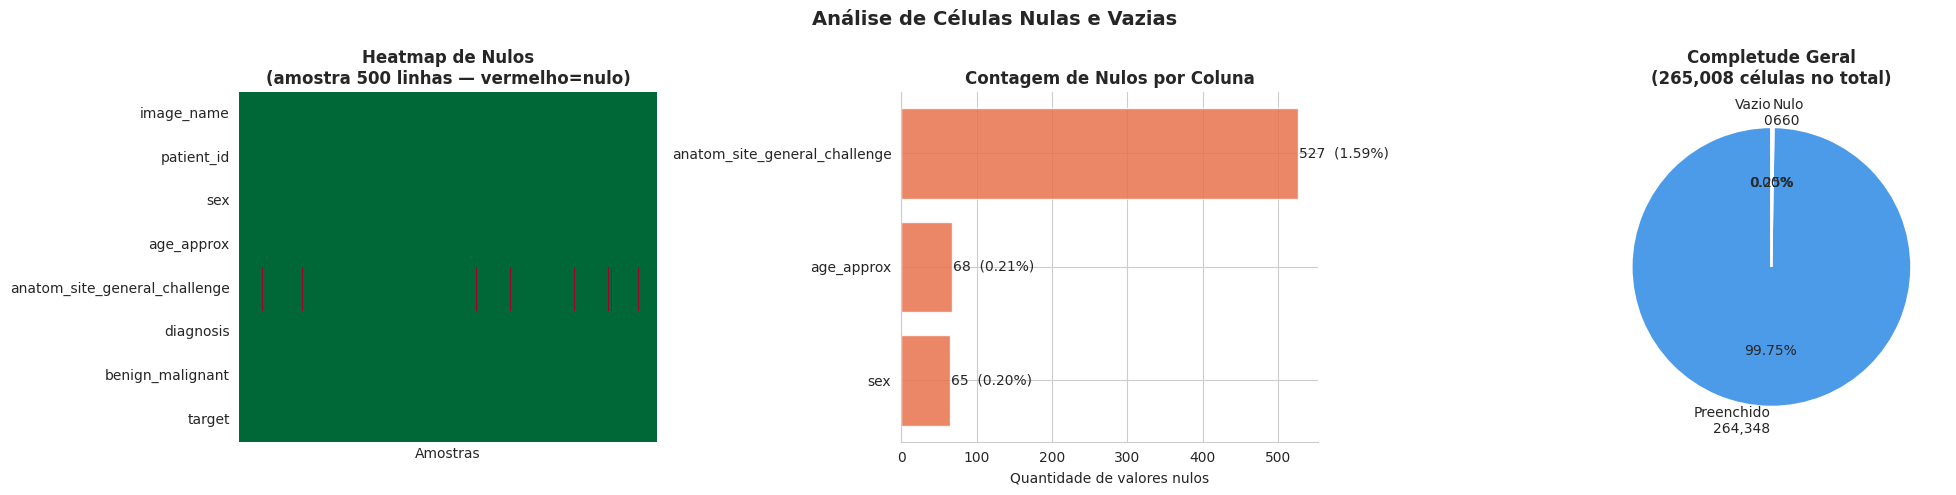


  Total de células  : 265,008
  Células nulas     : 660  (0.249%)
  Células vazias    : 0  (0.000%)
  Células válidas   : 264,348  (99.751%)


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
fig.suptitle('Análise de Células Nulas e Vazias', fontsize=14, fontweight='bold')

# ── Heatmap de nulos ──────────────────────────────────────────
nulo_matrix = df.isnull().astype(int)
# Amostra de 500 linhas para visualização
sample_idx = np.random.choice(len(df), min(500, len(df)), replace=False)
sns.heatmap(nulo_matrix.iloc[sample_idx].T,
            cbar=False, cmap='RdYlGn_r', ax=axes[0],
            yticklabels=df.columns, xticklabels=False)
axes[0].set_title('Heatmap de Nulos\n(amostra 500 linhas — vermelho=nulo)',
                   fontweight='bold')
axes[0].set_xlabel('Amostras')

# ── Barras: contagem de nulos por coluna ──────────────────────
nulos_count = df.isnull().sum().sort_values(ascending=True)
nulos_pct   = (nulos_count / len(df) * 100)
cols_com_nulo = nulos_count[nulos_count > 0]

if len(cols_com_nulo) > 0:
    bars = axes[1].barh(cols_com_nulo.index,
                         cols_com_nulo.values,
                         color='#E8714C', alpha=0.85, edgecolor='white')
    for b, (col, v) in zip(bars, cols_com_nulo.items()):
        pct = v / len(df) * 100
        axes[1].text(v + 1, b.get_y() + b.get_height()/2,
                     f'{v:,}  ({pct:.2f}%)', va='center', fontsize=10)
    axes[1].set_title('Contagem de Nulos por Coluna', fontweight='bold')
    axes[1].set_xlabel('Quantidade de valores nulos')
    axes[1].spines[['top','right']].set_visible(False)
else:
    axes[1].text(0.5, 0.5, '✅ Nenhum nulo encontrado!',
                  ha='center', va='center', fontsize=14, transform=axes[1].transAxes)
    axes[1].set_title('Nulos por Coluna', fontweight='bold')

# ── Pizza: completude geral ────────────────────────────────────
total_cells   = df.shape[0] * df.shape[1]
total_nulos   = df.isnull().sum().sum()
total_vazios  = sum(df[c].astype(str).str.strip().eq('').sum()
                    for c in df.select_dtypes(object).columns)
total_ok      = total_cells - total_nulos - total_vazios

axes[2].pie(
    [total_ok, total_nulos, total_vazios],
    labels=[f'Preenchido\n{total_ok:,}', f'Nulo\n{total_nulos:,}', f'Vazio\n{total_vazios:,}'],
    colors=['#4C9BE8', '#E8714C', '#E8D14C'],
    autopct='%1.2f%%', startangle=90,
    wedgeprops=dict(edgecolor='white', linewidth=1.5)
)
axes[2].set_title(f'Completude Geral\n({total_cells:,} células no total)', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(CFG['output_dir'], 'qualidade_01_nulos.png'), dpi=100)
plt.show()

print(f'\n  Total de células  : {total_cells:,}')
print(f'  Células nulas     : {total_nulos:,}  ({total_nulos/total_cells*100:.3f}%)')
print(f'  Células vazias    : {total_vazios:,}  ({total_vazios/total_cells*100:.3f}%)')
print(f'  Células válidas   : {total_ok:,}  ({total_ok/total_cells*100:.3f}%)')


## 3.3 – Detalhamento dos Nulos por Coluna

In [8]:
print('COLUNAS COM VALORES NULOS:')
print('─' * 55)
tem_nulo = False
for col in df.columns:
    n = df[col].isnull().sum()
    v = df[col].astype(str).str.strip().eq('').sum() if df[col].dtype == object else 0
    if n > 0 or v > 0:
        tem_nulo = True
        print(f'  {col:<42}  nulos={n:>5}  vazios={v:>4}  ({(n+v)/len(df)*100:.2f}%)')
        # Mostra distribuição dos nulos por classe
        if n > 0:
            nulo_por_classe = df[df[col].isnull()]['target'].value_counts()
            print(f'    └─ Nulos por classe → {nulo_por_classe.to_dict()}')

if not tem_nulo:
    print('  ✅ Nenhuma coluna com valores nulos ou vazios!')

print('\n\nCOLUNAS SEM NULOS:')
print('─' * 55)
for col in df.columns:
    n = df[col].isnull().sum()
    if n == 0:
        print(f'  ✅  {col}')


COLUNAS COM VALORES NULOS:
───────────────────────────────────────────────────────
  sex                                         nulos=   65  vazios=   0  (0.20%)
    └─ Nulos por classe → {0: 65}
  age_approx                                  nulos=   68  vazios=   0  (0.21%)
    └─ Nulos por classe → {0: 68}
  anatom_site_general_challenge               nulos=  527  vazios=   0  (1.59%)
    └─ Nulos por classe → {0: 518, 1: 9}


COLUNAS SEM NULOS:
───────────────────────────────────────────────────────
  ✅  image_name
  ✅  patient_id
  ✅  diagnosis
  ✅  benign_malignant
  ✅  target


## 3.4 – Verificação de Duplicatas

In [9]:
# Duplicatas exatas (todas as colunas)
dup_total = df.duplicated().sum()
# Duplicatas por image_name
dup_img   = df.duplicated(subset='image_name').sum()
# Mesmo paciente com mesma anatomia e target
dup_pac   = df.duplicated(subset=['patient_id','anatom_site_general_challenge','target']).sum()

print('VERIFICAÇÃO DE DUPLICATAS')
print('─' * 45)
print(f'  Linhas totais               : {len(df):,}')
print(f'  Duplicatas exatas (all cols) : {dup_total:,}', '✅' if dup_total==0 else '⚠️')
print(f'  Imagens duplicadas           : {dup_img:,}',   '✅' if dup_img==0 else '⚠️')
print(f'  Paciente×site×target dup.    : {dup_pac:,}')

if dup_total > 0:
    print('\n  Duplicatas encontradas:')
    display(df[df.duplicated(keep=False)].head(10))
else:
    print('\n  ✅ Nenhuma duplicata exata encontrada no dataset.')


VERIFICAÇÃO DE DUPLICATAS
─────────────────────────────────────────────
  Linhas totais               : 33,126
  Duplicatas exatas (all cols) : 0 ✅
  Imagens duplicadas           : 0 ✅
  Paciente×site×target dup.    : 26,364

  ✅ Nenhuma duplicata exata encontrada no dataset.


## 3.5 – Estatísticas Descritivas

In [10]:
print('VARIÁVEIS NUMÉRICAS')
display(df.describe().round(2))

print('\nVARIÁVEIS CATEGÓRICAS')
for col in df.select_dtypes(include='object').columns:
    print(f'\n  {col} ({df[col].nunique()} categorias):')
    print(df[col].value_counts().to_string())


VARIÁVEIS NUMÉRICAS


,age_approx,target
count,33058.00,33126.00
mean,48.87,0.02
std,14.38,0.13
min,0.00,0.00
25%,40.00,0.00
50%,50.00,0.00
75%,60.00,0.00
max,90.00,1.00



VARIÁVEIS CATEGÓRICAS

  image_name (33126 categorias):
image_name
ISIC_9999806    1
ISIC_2637011    1
ISIC_0015719    1
ISIC_0052212    1
ISIC_0068279    1
ISIC_0074268    1
ISIC_9988492    1
ISIC_9988559    1
ISIC_9989082    1
ISIC_9989156    1
ISIC_9989485    1
ISIC_9989617    1
ISIC_9989641    1
ISIC_9989680    1
ISIC_9986333    1
ISIC_9986563    1
ISIC_9986760    1
ISIC_9987485    1
ISIC_9987617    1
ISIC_9987757    1
ISIC_9987808    1
ISIC_9988236    1
ISIC_9983616    1
ISIC_9983657    1
ISIC_9983696    1
ISIC_9985141    1
ISIC_9985224    1
ISIC_9985776    1
ISIC_9985905    1
ISIC_9986040    1
ISIC_9981194    1
ISIC_9981394    1
ISIC_9981558    1
ISIC_9981925    1
ISIC_9982060    1
ISIC_9982091    1
ISIC_9982623    1
ISIC_9982953    1
ISIC_0099546    1
ISIC_0100550    1
ISIC_0103298    1
ISIC_0105145    1
ISIC_0106091    1
ISIC_0109415    1
ISIC_0109568    1
ISIC_0109703    1
ISIC_0096227    1
ISIC_0096328    1
ISIC_0097499    1
ISIC_0097500    1
ISIC_0097997    1
ISIC_0098198  

## 3.6 – 📋 Relatório de Qualidade — Resumo

In [11]:
print('╔' + '═'*61 + '╗')
print('║  RELATÓRIO DE QUALIDADE DOS DADOS                          ║')
print('╠' + '═'*61 + '╣')

checks = [
    ('Linhas totais',               f'{len(df):,}',                            ''),
    ('Colunas totais',              f'{df.shape[1]}',                           ''),
    ('Duplicatas exatas',           str(df.duplicated().sum()),
                                    '✅' if df.duplicated().sum()==0 else '⚠️'),
    ('Nulos em sex',                str(df['sex'].isnull().sum()),
                                    '⚠️ tratar' if df['sex'].isnull().sum()>0 else '✅'),
    ('Nulos em age_approx',         str(df['age_approx'].isnull().sum()),
                                    '⚠️ tratar' if df['age_approx'].isnull().sum()>0 else '✅'),
    ('Nulos em anatom_site',        str(df['anatom_site_general_challenge'].isnull().sum()),
                                    '⚠️ tratar' if df['anatom_site_general_challenge'].isnull().sum()>0 else '✅'),
    ('Nulos em target',             str(df['target'].isnull().sum()),
                                    '✅' if df['target'].isnull().sum()==0 else '❌ CRÍTICO'),
    ('Células vazias (str)',        str(total_vazios),
                                    '✅' if total_vazios==0 else '⚠️ tratar'),
    ('Completude geral',            f'{total_ok/total_cells*100:.3f}%',         ''),
]

for desc, val, status in checks:
    print(f'║  {desc:<32}  {val:>8}   {status:<12} ║')

print('╠' + '═'*61 + '╣')
print('║  AÇÕES NECESSÁRIAS NO PRÉ-PROCESSAMENTO:                   ║')
print('║  • sex        → imputar com MODA                          ║')
print('║  • age_approx → imputar com MEDIANA                       ║')
print('║  • anatom_site→ imputar com "unknown"                      ║')
print('║  • Categorias → LabelEncoder                              ║')
print('║  • age_approx → StandardScaler                            ║')
print('╚' + '═'*61 + '╝')


╔═════════════════════════════════════════════════════════════╗
║  RELATÓRIO DE QUALIDADE DOS DADOS                          ║
╠═════════════════════════════════════════════════════════════╣
║  Linhas totais                       33,126                ║
║  Colunas totais                           8                ║
║  Duplicatas exatas                        0   ✅            ║
║  Nulos em sex                            65   ⚠️ tratar    ║
║  Nulos em age_approx                     68   ⚠️ tratar    ║
║  Nulos em anatom_site                   527   ⚠️ tratar    ║
║  Nulos em target                          0   ✅            ║
║  Células vazias (str)                     0   ✅            ║
║  Completude geral                   99.751%                ║
╠═════════════════════════════════════════════════════════════╣
║  AÇÕES NECESSÁRIAS NO PRÉ-PROCESSAMENTO:                   ║
║  • sex        → imputar com MODA                          ║
║  • age_approx → imputar com MEDIANA                

---
# ⚖️ PARTE 4 — Análise de Balanceamento
> Verifica a distribuição das classes e o impacto do desbalanceamento.


## 4.1 – Distribuição das Classes (Target)

In [12]:
total = len(df)
n_ben = (df['target'] == 0).sum()
n_mal = (df['target'] == 1).sum()
razao = n_ben // n_mal

print('╔' + '═'*55 + '╗')
print('║  DISTRIBUIÇÃO DAS CLASSES                             ║')
print('╠' + '═'*55 + '╣')
print(f'║  Total de amostras  : {total:>10,}                   ║')
print(f'║  Benigno  (0)       : {n_ben:>10,}   ({n_ben/total*100:>6.2f}%)       ║')
print(f'║  Maligno  (1)       : {n_mal:>10,}   ({n_mal/total*100:>6.2f}%)       ║')
print(f'║  Razão B:M          :    {razao:>5}:1                    ║')
print('╠' + '═'*55 + '╣')
if n_mal/total < 0.10:
    print('║  ⚠️  DESBALANCEAMENTO EXTREMO detectado!              ║')
    print('║  Estratégias obrigatórias:                            ║')
    print('║    ① WeightedRandomSampler nos batches de treino     ║')
    print('║    ② BCEWithLogitsLoss(pos_weight > 1)               ║')
    print('║    ③ Threshold < 0.5 para maior sensibilidade        ║')
    print('║    ④ Augmentação agressiva na classe minoritária     ║')
elif n_mal/total < 0.30:
    print('║  ⚠️  DESBALANCEAMENTO MODERADO detectado.            ║')
else:
    print('║  ✅ Classes balanceadas.                              ║')
print('╚' + '═'*55 + '╝')


╔═══════════════════════════════════════════════════════╗
║  DISTRIBUIÇÃO DAS CLASSES                             ║
╠═══════════════════════════════════════════════════════╣
║  Total de amostras  :     33,126                   ║
║  Benigno  (0)       :     32,542   ( 98.24%)       ║
║  Maligno  (1)       :        584   (  1.76%)       ║
║  Razão B:M          :       55:1                    ║
╠═══════════════════════════════════════════════════════╣
║  ⚠️  DESBALANCEAMENTO EXTREMO detectado!              ║
║  Estratégias obrigatórias:                            ║
║    ① WeightedRandomSampler nos batches de treino     ║
║    ② BCEWithLogitsLoss(pos_weight > 1)               ║
║    ③ Threshold < 0.5 para maior sensibilidade        ║
║    ④ Augmentação agressiva na classe minoritária     ║
╚═══════════════════════════════════════════════════════╝


## 4.2 – Visualização do Desbalanceamento

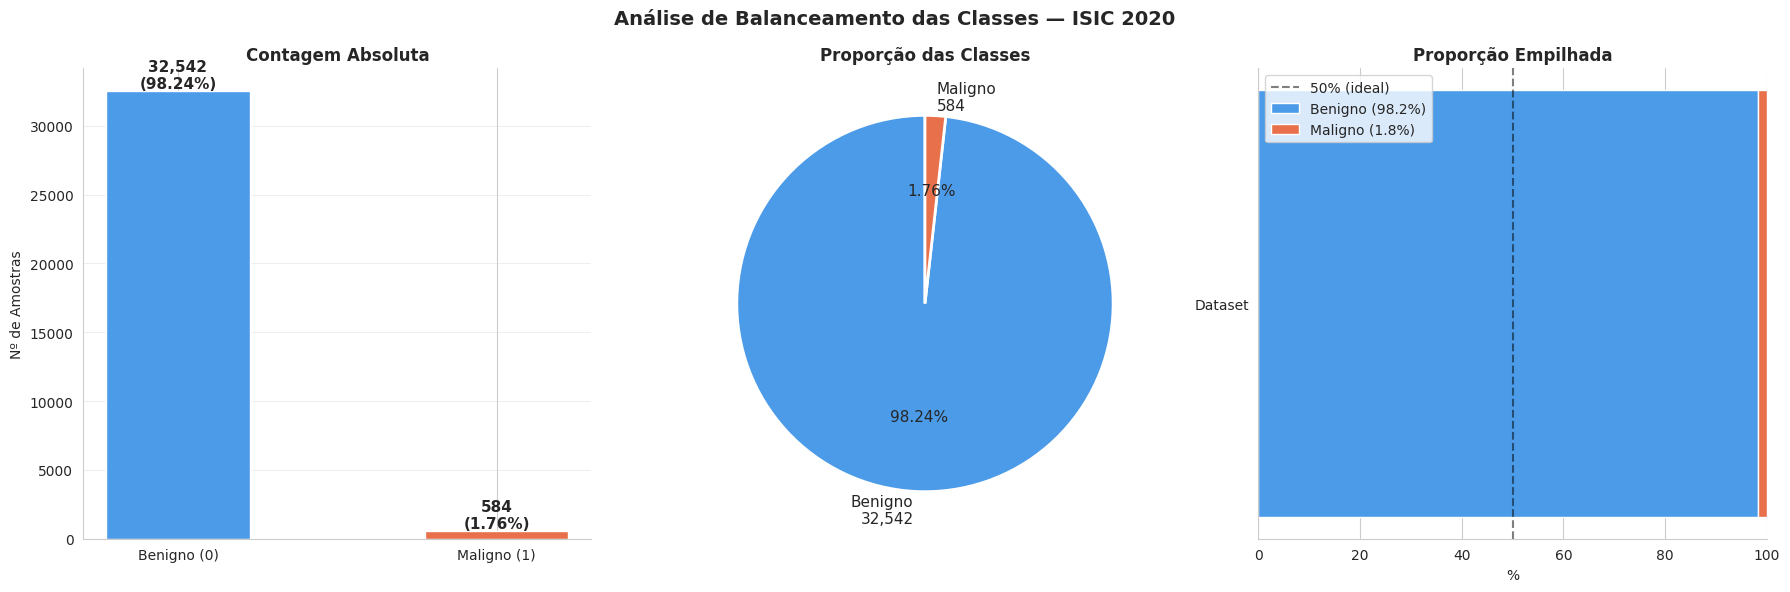

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Análise de Balanceamento das Classes — ISIC 2020',
              fontsize=14, fontweight='bold')

# ── Barras absolutas ──────────────────────────────────────────
bars = axes[0].bar(['Benigno (0)', 'Maligno (1)'], [n_ben, n_mal],
                    color=['#4C9BE8', '#E8714C'], edgecolor='white', width=0.45)
for b, v in zip(bars, [n_ben, n_mal]):
    axes[0].text(b.get_x()+b.get_width()/2, b.get_height()+200,
                  f'{v:,}\n({v/total*100:.2f}%)', ha='center', fontsize=11,
                  fontweight='bold')
axes[0].set_title('Contagem Absoluta', fontweight='bold')
axes[0].set_ylabel('Nº de Amostras'); axes[0].grid(axis='y', alpha=0.3)
axes[0].spines[['top','right']].set_visible(False)

# ── Pizza ─────────────────────────────────────────────────────
axes[1].pie([n_ben, n_mal],
             labels=[f'Benigno\n{n_ben:,}', f'Maligno\n{n_mal:,}'],
             colors=['#4C9BE8', '#E8714C'],
             autopct='%1.2f%%', startangle=90,
             wedgeprops=dict(edgecolor='white', linewidth=2),
             textprops={'fontsize': 11})
axes[1].set_title('Proporção das Classes', fontweight='bold')

# ── Barra de proporção empilhada ──────────────────────────────
axes[2].barh(['Dataset'], [n_ben/total*100], color='#4C9BE8',
              label=f'Benigno ({n_ben/total*100:.1f}%)')
axes[2].barh(['Dataset'], [n_mal/total*100], left=[n_ben/total*100],
              color='#E8714C', label=f'Maligno ({n_mal/total*100:.1f}%)')
axes[2].axvline(50, color='black', ls='--', alpha=0.5, label='50% (ideal)')
axes[2].set_title('Proporção Empilhada', fontweight='bold')
axes[2].set_xlabel('%'); axes[2].legend(fontsize=10); axes[2].set_xlim(0, 100)
axes[2].spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(CFG['output_dir'], 'balanceamento_01_classes.png'), dpi=100)
plt.show()


## 4.3 – Balanceamento por Feature Categórica

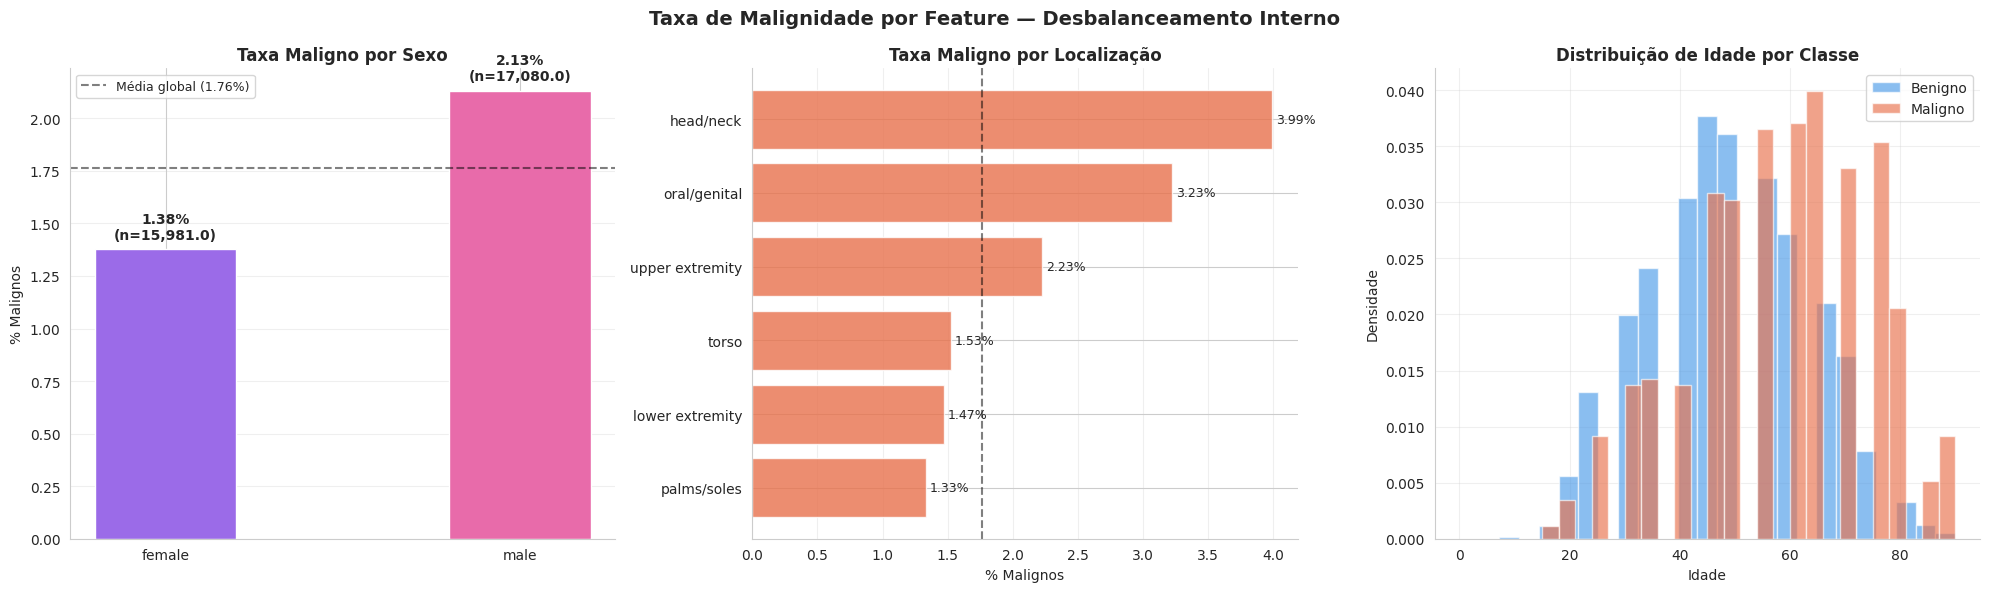

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('Taxa de Malignidade por Feature — Desbalanceamento Interno',
              fontsize=14, fontweight='bold')

# Taxa por sexo
taxa_sex = df.groupby('sex')['target'].agg(['sum','count'])
taxa_sex['taxa'] = taxa_sex['sum'] / taxa_sex['count'] * 100
axes[0].bar(taxa_sex.index, taxa_sex['taxa'], color=['#9B6BE8','#E86BAA'],
             edgecolor='white', width=0.4)
for i, (idx, row) in enumerate(taxa_sex.iterrows()):
    axes[0].text(i, row['taxa']+0.05,
                  f"{row['taxa']:.2f}%\n(n={row['count']:,})",
                  ha='center', fontsize=10, fontweight='bold')
axes[0].axhline(n_mal/total*100, color='black', ls='--', alpha=0.5,
                 label=f'Média global ({n_mal/total*100:.2f}%)')
axes[0].set_title('Taxa Maligno por Sexo', fontweight='bold')
axes[0].set_ylabel('% Malignos'); axes[0].legend(fontsize=9)
axes[0].grid(axis='y', alpha=0.3); axes[0].spines[['top','right']].set_visible(False)

# Taxa por localização
taxa_site = (df.groupby('anatom_site_general_challenge')['target']
               .mean().mul(100).sort_values(ascending=True))
axes[1].barh(taxa_site.index, taxa_site.values, color='#E8714C', alpha=0.8)
for i, (idx, v) in enumerate(taxa_site.items()):
    axes[1].text(v+0.03, i, f'{v:.2f}%', va='center', fontsize=9)
axes[1].axvline(n_mal/total*100, color='black', ls='--', alpha=0.5)
axes[1].set_title('Taxa Maligno por Localização', fontweight='bold')
axes[1].set_xlabel('% Malignos')
axes[1].grid(axis='x', alpha=0.3); axes[1].spines[['top','right']].set_visible(False)

# Distribuição de idade por classe
for cls, lbl, cor in [(0,'Benigno','#4C9BE8'),(1,'Maligno','#E8714C')]:
    axes[2].hist(df[df['target']==cls]['age_approx'].dropna(),
                  bins=25, alpha=0.65, color=cor, label=lbl, density=True)
axes[2].set_title('Distribuição de Idade por Classe', fontweight='bold')
axes[2].set_xlabel('Idade'); axes[2].set_ylabel('Densidade')
axes[2].legend(); axes[2].grid(alpha=0.3)
axes[2].spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(CFG['output_dir'], 'balanceamento_02_por_feature.png'), dpi=100)
plt.show()


## 4.4 – Impacto das Estratégias de Balanceamento nos Batches
> Demonstra visualmente o que acontece COM e SEM `WeightedRandomSampler`.


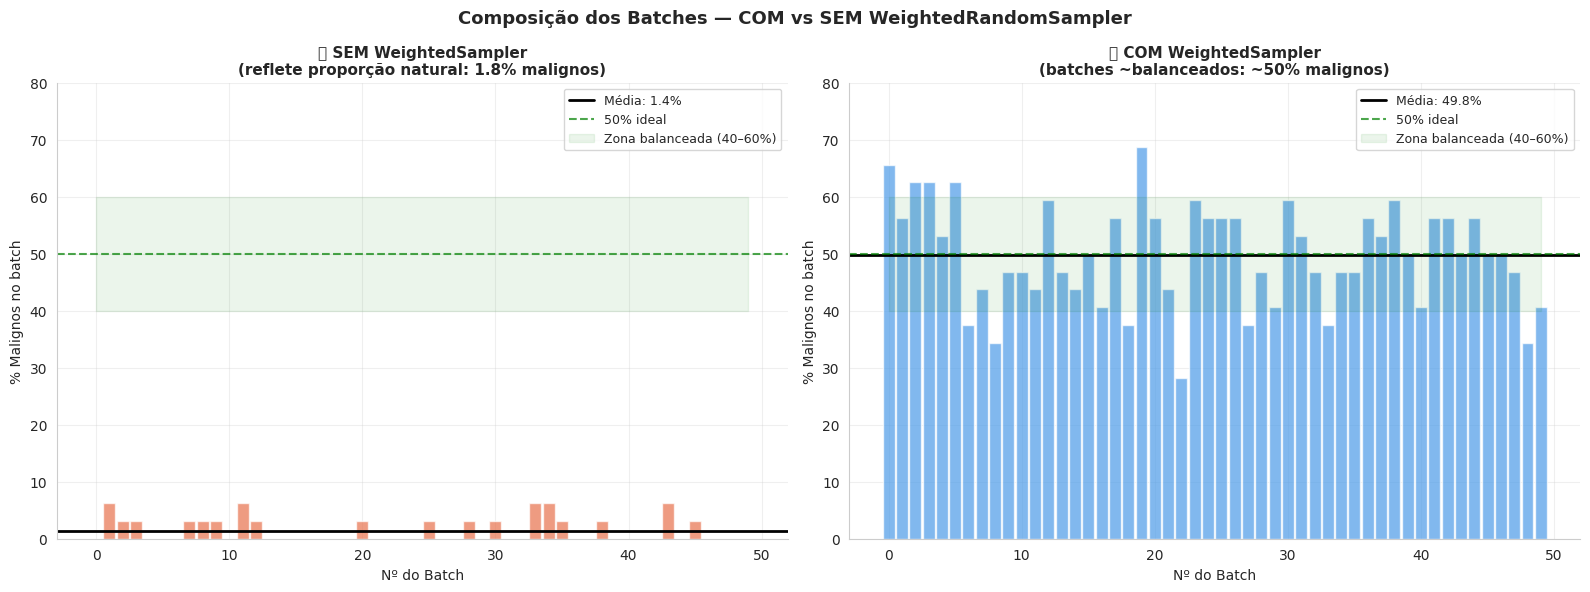

Sem sampler → média 1.4% malignos/batch → modelo aprende a ignorar malignos!
Com sampler → média 49.8% malignos/batch → modelo aprende as duas classes!


In [15]:
# Simula composição dos batches COM e SEM WeightedRandomSampler
np.random.seed(42)
BATCH_SIZE = 32
N_BATCHES  = 50

# Proporções reais do dataset
prop_mal = n_mal / total
prop_ben = n_ben / total

# SEM sampler: batches aleatórios (refletem proporção natural)
batches_sem = [np.random.binomial(BATCH_SIZE, prop_mal) for _ in range(N_BATCHES)]

# COM sampler: batches ~balanceados (50/50)
batches_com = [np.random.binomial(BATCH_SIZE, 0.50) for _ in range(N_BATCHES)]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Composição dos Batches — COM vs SEM WeightedRandomSampler',
              fontsize=13, fontweight='bold')

for ax, batches, titulo, cor, media_esperada in [
    (axes[0], batches_sem,
     f'❌ SEM WeightedSampler\n(reflete proporção natural: {prop_mal*100:.1f}% malignos)',
     '#E8714C', prop_mal*BATCH_SIZE),
    (axes[1], batches_com,
     f'✅ COM WeightedSampler\n(batches ~balanceados: ~50% malignos)',
     '#4C9BE8', BATCH_SIZE*0.5),
]:
    pcts = [b/BATCH_SIZE*100 for b in batches]
    ax.bar(range(N_BATCHES), pcts, color=cor, alpha=0.7, width=0.9)
    ax.axhline(np.mean(pcts), color='black', lw=2,
                label=f'Média: {np.mean(pcts):.1f}%')
    ax.axhline(50, color='green', ls='--', lw=1.5, alpha=0.7, label='50% ideal')
    ax.fill_between(range(N_BATCHES), 40, 60, alpha=0.08, color='green',
                     label='Zona balanceada (40–60%)')
    ax.set_title(titulo, fontweight='bold', fontsize=11)
    ax.set_xlabel('Nº do Batch'); ax.set_ylabel('% Malignos no batch')
    ax.set_ylim(0, 80); ax.legend(fontsize=9); ax.grid(alpha=0.3)
    ax.spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(CFG['output_dir'], 'balanceamento_03_batches.png'), dpi=100)
plt.show()

print(f'Sem sampler → média {np.mean(batches_sem)/BATCH_SIZE*100:.1f}% malignos/batch '
      f'→ modelo aprende a ignorar malignos!')
print(f'Com sampler → média {np.mean(batches_com)/BATCH_SIZE*100:.1f}% malignos/batch '
      f'→ modelo aprende as duas classes!')


## 4.5 – Análise de Pacientes (Risco de Data Leakage)

ANÁLISE DE PACIENTES
──────────────────────────────────────────────────
  Pacientes únicos           : 2,056
  Imagens por paciente       : min=2  max=115  média=16.1
  Pacientes com maligno      : 428
  Pacientes somente benigno  : 1,628

  ⚠️  RISCO DE DATA LEAKAGE:
  Um paciente pode ter até 115 imagens.
  Split aleatório colocaria imagens do MESMO paciente
  em treino E teste → modelo aprende o paciente, não a doença!

  ✅  SOLUÇÃO: GroupShuffleSplit por patient_id
  Garante que NENHUM paciente apareça em dois conjuntos.


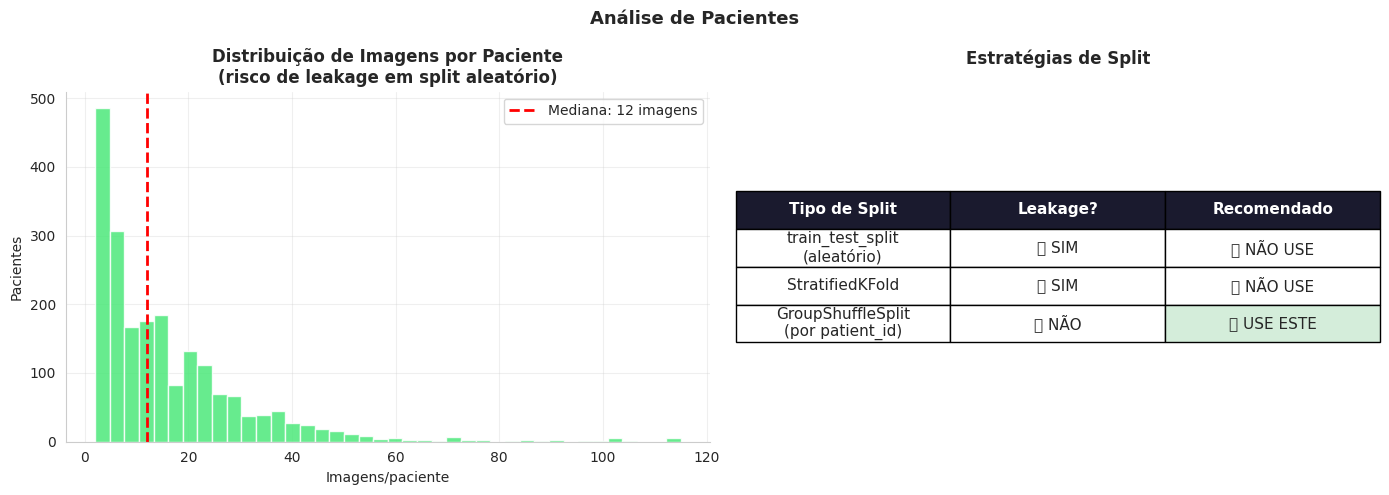

In [16]:
n_pac       = df['patient_id'].nunique()
imgs_pp     = df.groupby('patient_id').size()
pac_mal     = df[df['target']==1]['patient_id'].nunique()
pac_so_ben  = df.groupby('patient_id')['target'].max() == 0

print('ANÁLISE DE PACIENTES')
print('─' * 50)
print(f'  Pacientes únicos           : {n_pac:,}')
print(f'  Imagens por paciente       : min={imgs_pp.min()}  max={imgs_pp.max()}  média={imgs_pp.mean():.1f}')
print(f'  Pacientes com maligno      : {pac_mal}')
print(f'  Pacientes somente benigno  : {pac_so_ben.sum():,}')
print()
print('  ⚠️  RISCO DE DATA LEAKAGE:')
print(f'  Um paciente pode ter até {imgs_pp.max()} imagens.')
print('  Split aleatório colocaria imagens do MESMO paciente')
print('  em treino E teste → modelo aprende o paciente, não a doença!')
print()
print('  ✅  SOLUÇÃO: GroupShuffleSplit por patient_id')
print('  Garante que NENHUM paciente apareça em dois conjuntos.')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Análise de Pacientes', fontsize=13, fontweight='bold')

ax1.hist(imgs_pp.values, bins=40, color='#4CE87A', edgecolor='white', alpha=0.85)
ax1.axvline(imgs_pp.median(), color='red', ls='--', lw=2,
             label=f'Mediana: {imgs_pp.median():.0f} imagens')
ax1.set_title('Distribuição de Imagens por Paciente\n(risco de leakage em split aleatório)',
               fontweight='bold')
ax1.set_xlabel('Imagens/paciente'); ax1.set_ylabel('Pacientes')
ax1.legend(); ax1.grid(alpha=0.3)
ax1.spines[['top','right']].set_visible(False)

# Diagrama comparativo dos splits
ax2.axis('off')
tabela = [
    ['Tipo de Split', 'Leakage?', 'Recomendado'],
    ['train_test_split\n(aleatório)', '❌ SIM', '❌ NÃO USE'],
    ['StratifiedKFold', '❌ SIM', '❌ NÃO USE'],
    ['GroupShuffleSplit\n(por patient_id)', '✅ NÃO', '✅ USE ESTE'],
]
tbl = ax2.table(cellText=tabela[1:], colLabels=tabela[0],
                 loc='center', cellLoc='center')
tbl.auto_set_font_size(False); tbl.set_fontsize(11); tbl.scale(1, 2.5)
tbl[0,0].set_facecolor('#1a1a2e'); tbl[0,0].set_text_props(color='white', fontweight='bold')
tbl[0,1].set_facecolor('#1a1a2e'); tbl[0,1].set_text_props(color='white', fontweight='bold')
tbl[0,2].set_facecolor('#1a1a2e'); tbl[0,2].set_text_props(color='white', fontweight='bold')
tbl[3,2].set_facecolor('#d4edda')
ax2.set_title('Estratégias de Split', fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig(os.path.join(CFG['output_dir'], 'balanceamento_04_pacientes.png'), dpi=100)
plt.show()


---
# 🔧 PARTE 5 — Pré-processamento Completo
> Cada decisão é baseada nos achados das Partes 3 e 4.


## 5.1 – Tratamento de Nulos (com comparação before/after)
| Feature | Estratégia | Justificativa |
|---|---|---|
| `sex` | Moda (`male`) | Poucos nulos (0.2%), distribuição quase uniforme |
| `age_approx` | Mediana | Distribuição levemente assimétrica — mediana robusta a outliers |
| `anatom_site` | `'unknown'` | 1.6% nulos — não desprezível, categoria própria preserva info |


In [17]:
# ── Estado ANTES do tratamento ───────────────────────────────
nulos_antes = df[['sex','age_approx','anatom_site_general_challenge']].isnull().sum()

# ── Imputação ────────────────────────────────────────────────
moda_sex   = df['sex'].mode()[0]
median_age = df['age_approx'].median()

df['sex']        = df['sex'].fillna(moda_sex)
df['age_approx'] = df['age_approx'].fillna(median_age)
df['anatom_site_general_challenge'] = \
    df['anatom_site_general_challenge'].fillna('unknown')

# ── Estado DEPOIS do tratamento ──────────────────────────────
nulos_depois = df[['sex','age_approx','anatom_site_general_challenge']].isnull().sum()

# ── Comparação before/after ───────────────────────────────────
comp = pd.DataFrame({
    'Antes (nulos)' : nulos_antes,
    'Depois (nulos)': nulos_depois,
    'Estratégia'   : [f'fillna("{moda_sex}")', f'fillna({median_age})', 'fillna("unknown")'],
})
print('ANTES × DEPOIS DO TRATAMENTO DE NULOS')
display(comp.style
    .background_gradient(subset=['Antes (nulos)'], cmap='Reds')
    .background_gradient(subset=['Depois (nulos)'], cmap='Greens_r')
    .set_caption('Verde = 0 nulos restantes ✅'))

# Verifica se todos foram tratados
restantes = df.isnull().sum().sum()
print(f'\nNulos restantes no dataset: {restantes}')
print('✅ Todos os nulos foram tratados!' if restantes == 0 else f'⚠️ {restantes} nulos ainda presentes')


ANTES × DEPOIS DO TRATAMENTO DE NULOS


,Antes (nulos),Depois (nulos),Estratégia
sex,65,0,"fillna(""male"")"
age_approx,68,0,fillna(50.0)
anatom_site_general_challenge,527,0,"fillna(""unknown"")"



Nulos restantes no dataset: 0
✅ Todos os nulos foram tratados!


## 5.2 – Encoding e Normalização (com visualização before/after)


ANTES DO ENCODING:


,sex,age_approx,anatom_site_general_challenge
0,male,45.0,head/neck
1,female,45.0,upper extremity
2,female,50.0,lower extremity
3,female,45.0,head/neck
4,female,55.0,upper extremity



APÓS O ENCODING:


,sex,sex_enc,age_approx,age_norm,anatom_site_general_challenge,site_enc
0,male,1,45.0,-0.269559,head/neck,0
1,female,0,45.0,-0.269559,upper extremity,6
2,female,0,50.0,0.078498,lower extremity,1
3,female,0,45.0,-0.269559,head/neck,0
4,female,0,55.0,0.426555,upper extremity,6



Mapeamentos:
  sex  : {'female': np.int64(0), 'male': np.int64(1)}
  site : {'head/neck': np.int64(0), 'lower extremity': np.int64(1), 'oral/genital': np.int64(2), 'palms/soles': np.int64(3), 'torso': np.int64(4), 'unknown': np.int64(5), 'upper extremity': np.int64(6)}
  age  : média=48.9, std=14.4 → normalizado N(0,1)


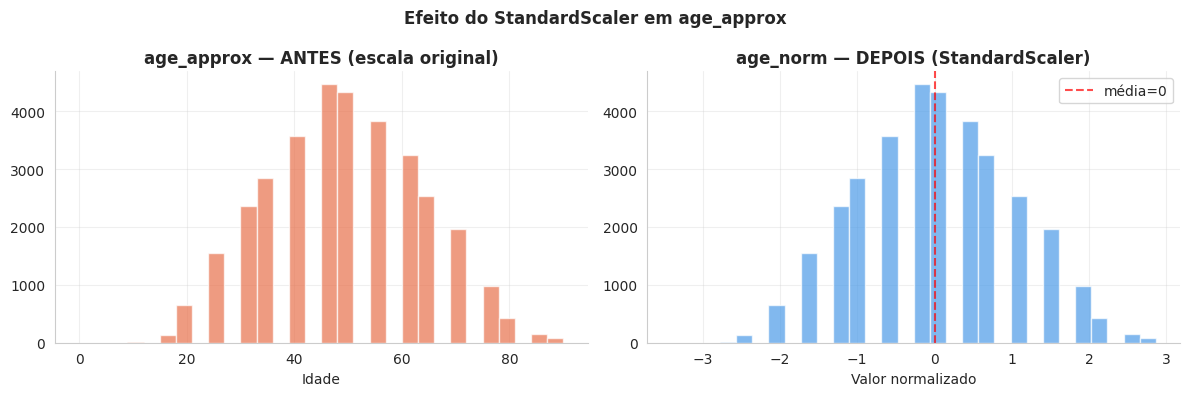

In [18]:
# ── Before ───────────────────────────────────────────────────
print('ANTES DO ENCODING:')
display(df[['sex','age_approx','anatom_site_general_challenge']].head(5))

# ── LabelEncoder ─────────────────────────────────────────────
le_sex  = LabelEncoder().fit(df['sex'])
le_site = LabelEncoder().fit(df['anatom_site_general_challenge'])
scaler  = StandardScaler().fit(df[['age_approx']])

df['sex_enc']  = le_sex.transform(df['sex'])
df['site_enc'] = le_site.transform(df['anatom_site_general_challenge'])
df['age_norm'] = scaler.transform(df[['age_approx']])

TAB_COLS = ['age_norm', 'sex_enc', 'site_enc']

print('\nAPÓS O ENCODING:')
display(df[['sex','sex_enc','age_approx','age_norm',
             'anatom_site_general_challenge','site_enc']].head(5))

print(f'\nMapeamentos:')
print(f'  sex  : {dict(zip(le_sex.classes_, le_sex.transform(le_sex.classes_)))}')
print(f'  site : {dict(zip(le_site.classes_, le_site.transform(le_site.classes_)))}')
print(f'  age  : média={scaler.mean_[0]:.1f}, std={scaler.scale_[0]:.1f} → normalizado N(0,1)')

# Visualiza distribuição antes/depois da normalização
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df['age_approx'], bins=30, color='#E8714C', alpha=0.7, edgecolor='white')
axes[0].set_title('age_approx — ANTES (escala original)', fontweight='bold')
axes[0].set_xlabel('Idade'); axes[0].grid(alpha=0.3)
axes[1].hist(df['age_norm'], bins=30, color='#4C9BE8', alpha=0.7, edgecolor='white')
axes[1].set_title('age_norm — DEPOIS (StandardScaler)', fontweight='bold')
axes[1].set_xlabel('Valor normalizado'); axes[1].grid(alpha=0.3)
axes[1].axvline(0, color='red', ls='--', alpha=0.7, label='média=0')
axes[1].legend()
for ax in axes: ax.spines[['top','right']].set_visible(False)
plt.suptitle('Efeito do StandardScaler em age_approx', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(CFG['output_dir'], 'preproc_01_encoding.png'), dpi=100)
plt.show()


## 5.3 – Split por Paciente (GroupShuffleSplit)

In [19]:
def split_por_paciente(df, test_size=CFG['test_size'],
                        val_size=CFG['val_size'], seed=CFG['seed']):
    # Teste
    gss = GroupShuffleSplit(1, test_size=test_size, random_state=seed)
    tr_v, ts = next(gss.split(np.arange(len(df)),
                               df['target'].values,
                               groups=df['patient_id'].values))
    df_tv   = df.iloc[tr_v].reset_index(drop=True)
    df_test = df.iloc[ts].reset_index(drop=True)

    # Validação
    vf = val_size / (1 - test_size)
    gss2 = GroupShuffleSplit(1, test_size=vf, random_state=seed)
    tr2, vl2 = next(gss2.split(np.arange(len(df_tv)),
                                df_tv['target'].values,
                                groups=df_tv['patient_id'].values))
    df_train = df_tv.iloc[tr2].reset_index(drop=True)
    df_val   = df_tv.iloc[vl2].reset_index(drop=True)

    # Verificação anti-leakage
    assert len(set(df_train['patient_id']) & set(df_test['patient_id'])) == 0, \
        '❌ LEAKAGE: paciente em treino e teste!'
    assert len(set(df_val['patient_id'])   & set(df_test['patient_id'])) == 0, \
        '❌ LEAKAGE: paciente em val e teste!'
    return df_train, df_val, df_test

df_train, df_val, df_test = split_por_paciente(df)

# Tabela de comparação
splits_info = pd.DataFrame({
    'Split'     : ['Treino', 'Validação', 'Teste'],
    'Amostras'  : [len(df_train), len(df_val), len(df_test)],
    '%'         : [f'{len(df_train)/len(df)*100:.1f}%',
                   f'{len(df_val)/len(df)*100:.1f}%',
                   f'{len(df_test)/len(df)*100:.1f}%'],
    'Pacientes' : [df_train['patient_id'].nunique(),
                   df_val['patient_id'].nunique(),
                   df_test['patient_id'].nunique()],
    'Malignos'  : [df_train['target'].sum(),
                   df_val['target'].sum(),
                   df_test['target'].sum()],
    '% Maligno' : [f'{df_train["target"].mean()*100:.2f}%',
                   f'{df_val["target"].mean()*100:.2f}%',
                   f'{df_test["target"].mean()*100:.2f}%'],
    'Leakage?'  : ['✅ NÃO'] * 3,
})
display(splits_info)

n_tab = len(TAB_COLS)
print(f'\nFeatures tabulares: {TAB_COLS}')
print(f'Anti-leakage verificado: ✅')


,Split,Amostras,%,Pacientes,Malignos,% Maligno,Leakage?
0,Treino,23257,70.2%,1438,427,1.84%,✅ NÃO
1,Validação,4835,14.6%,309,70,1.45%,✅ NÃO
2,Teste,5034,15.2%,309,87,1.73%,✅ NÃO



Features tabulares: ['age_norm', 'sex_enc', 'site_enc']
Anti-leakage verificado: ✅


## 5.4 – Dataset PyTorch e DataLoaders
> Augmentação de treino + WeightedRandomSampler para balanceamento dos batches.


In [20]:
IMAGENET_NORM = transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])

TRAIN_TF = transforms.Compose([
    transforms.Resize((CFG['img_size'], CFG['img_size'])),  # 128 → 224
    transforms.RandomHorizontalFlip(0.5),
    transforms.RandomVerticalFlip(0.3),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.05),
    transforms.RandomAffine(degrees=0, translate=(0.1,0.1), scale=(0.9,1.1)),
    transforms.ToTensor(), IMAGENET_NORM,
])
VAL_TF = transforms.Compose([
    transforms.Resize((CFG['img_size'], CFG['img_size'])),
    transforms.ToTensor(), IMAGENET_NORM,
])

class ISICDataset(Dataset):
    def __init__(self, df, zip_path, tab_cols, mode='train'):
        self.df=df.reset_index(drop=True); self.zip_path=zip_path
        self.tab_cols=tab_cols; self.tf=TRAIN_TF if mode=='train' else VAL_TF
        self._zf=None
    def _get_zf(self):
        if self._zf is None: self._zf=zipfile.ZipFile(self.zip_path,'r')
        return self._zf
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row=self.df.iloc[i]
        try:
            with self._get_zf().open(f"images/{row['image_name']}.jpg") as fp:
                img=Image.open(io.BytesIO(fp.read())).convert('RGB')
        except: img=Image.new('RGB',(CFG['img_size'],CFG['img_size']))
        return (self.tf(img),
                torch.tensor(row[self.tab_cols].values.astype(np.float32)),
                torch.tensor(float(row['target'])))
    def __del__(self):
        if self._zf: self._zf.close()

def criar_loaders(df_tr, df_vl, df_ts, zip_path, tab_cols):
    ds_tr=ISICDataset(df_tr,zip_path,tab_cols,'train')
    ds_vl=ISICDataset(df_vl,zip_path,tab_cols,'val')
    ds_ts=ISICDataset(df_ts,zip_path,tab_cols,'test')
    cnts=df_tr['target'].value_counts()
    w=df_tr['target'].map({c:1.0/cnts[c] for c in cnts.index}).values
    sampler=WeightedRandomSampler(torch.DoubleTensor(w),len(w),replacement=True)
    kw=dict(num_workers=CFG['num_workers'],pin_memory=(DEVICE.type=='cuda'))
    dl_tr=DataLoader(ds_tr,CFG['batch_size'],sampler=sampler,**kw)
    dl_vl=DataLoader(ds_vl,CFG['batch_size']*2,shuffle=False,**kw)
    dl_ts=DataLoader(ds_ts,CFG['batch_size']*2,shuffle=False,**kw)
    return dl_tr, dl_vl, dl_ts

dl_tr, dl_vl, dl_ts = criar_loaders(
    df_train, df_val, df_test, CFG['zip_path'], TAB_COLS
)
print(f'DataLoaders criados:')
print(f'  Treino   : {len(dl_tr):,} batches  (WeightedSampler ✅)')
print(f'  Validação: {len(dl_vl):,} batches')
print(f'  Teste    : {len(dl_ts):,} batches')


DataLoaders criados:
  Treino   : 727 batches  (WeightedSampler ✅)
  Validação: 76 batches
  Teste    : 79 batches


## 5.5 – 📋 Relatório Final do Pré-processamento

In [21]:
print('╔' + '═'*63 + '╗')
print('║  RELATÓRIO FINAL DE PRÉ-PROCESSAMENTO                       ║')
print('╠' + '═'*63 + '╣')
print('║  QUALIDADE DOS DADOS                                         ║')
print(f'║    Nulos tratados      : sex ({df_raw["sex"].isnull().sum()}) + '
      f'age ({df_raw["age_approx"].isnull().sum()}) + site ({df_raw["anatom_site_general_challenge"].isnull().sum()}) ║')
print(f'║    Duplicatas          : {df_raw.duplicated().sum()} (nenhuma removida) {" "*24} ║')
print(f'║    Nulos após trat.    : {df.isnull().sum().sum()} ✅ {" "*36} ║')
print('╠' + '═'*63 + '╣')
print('║  BALANCEAMENTO                                               ║')
print(f'║    Razão B:M original  : {razao}:1 ({'⚠️ desbalanceado'}) {" "*18} ║')
print(f'║    WeightedSampler     : ✅ ativo (~50% maligno/batch) {" "*9} ║')
print(f'║    pos_weight (loss)   : {CFG["pos_weight"]} (penaliza FN) {" "*27} ║')
print(f'║    Threshold           : {CFG["threshold"]} (sensível a maligno) {" "*22} ║')
print('╠' + '═'*63 + '╣')
print('║  ENCODING & NORMALIZAÇÃO                                     ║')
print(f'║    sex       : LabelEncoder ({dict(zip(le_sex.classes_, le_sex.transform(le_sex.classes_)))}) {" "*18} ║')
print(f'║    site      : LabelEncoder ({le_site.classes_.shape[0]} categorias) {" "*22} ║')
print(f'║    age       : StandardScaler → N(0,1) {" "*24} ║')
print('╠' + '═'*63 + '╣')
print('║  SPLIT (por patient_id — sem data leakage)                   ║')
print(f'║    Treino    : {len(df_train):>6,} amostras  {df_train["target"].mean()*100:.2f}% malignos {" "*16} ║')
print(f'║    Validação : {len(df_val):>6,} amostras  {df_val["target"].mean()*100:.2f}% malignos {" "*16} ║')
print(f'║    Teste     : {len(df_test):>6,} amostras  {df_test["target"].mean()*100:.2f}% malignos {" "*16} ║')
print('╚' + '═'*63 + '╝')
print('\n✅ Pré-processamento concluído — pronto para modelagem!')


╔═══════════════════════════════════════════════════════════════╗
║  RELATÓRIO FINAL DE PRÉ-PROCESSAMENTO                       ║
╠═══════════════════════════════════════════════════════════════╣
║  QUALIDADE DOS DADOS                                         ║
║    Nulos tratados      : sex (65) + age (68) + site (527) ║
║    Duplicatas          : 0 (nenhuma removida)                          ║
║    Nulos após trat.    : 0 ✅                                      ║
╠═══════════════════════════════════════════════════════════════╣
║  BALANCEAMENTO                                               ║
║    Razão B:M original  : 55:1 (⚠️ desbalanceado)                    ║
║    WeightedSampler     : ✅ ativo (~50% maligno/batch)           ║
║    pos_weight (loss)   : 10.0 (penaliza FN)                             ║
║    Threshold           : 0.3 (sensível a maligno)                        ║
╠═══════════════════════════════════════════════════════════════╣
║  ENCODING & NORMALIZAÇÃO                

---
# 🖼️ PARTE 6 — EDA Visual (Imagens)


## 6.1 – Amostras de Imagens por Classe

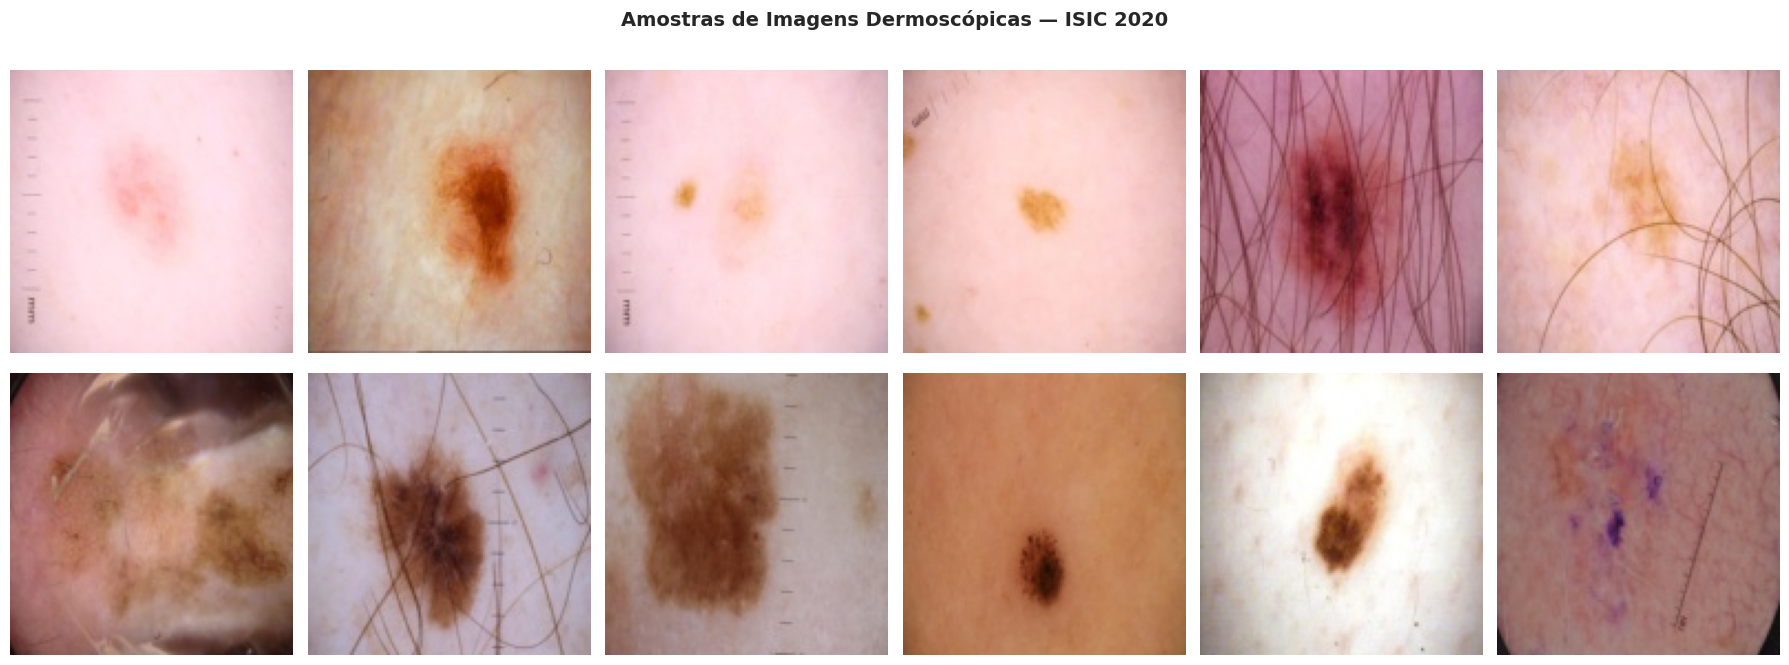

In [22]:
amostras_ben = df[df['target']==0]['image_name'].sample(6, random_state=42).tolist()
amostras_mal = df[df['target']==1]['image_name'].sample(6, random_state=42).tolist()
fig, axes = plt.subplots(2, 6, figsize=(18, 7))
fig.suptitle('Amostras de Imagens Dermoscópicas — ISIC 2020', fontsize=14, fontweight='bold')
with zipfile.ZipFile(CFG['zip_path'], 'r') as zf:
    for row_axes, names, lbl, cor in [
        (axes[0], amostras_ben, 'BENIGNO (0)', '#4C9BE8'),
        (axes[1], amostras_mal, 'MALIGNO (1)', '#E8714C'),
    ]:
        for j, img_name in enumerate(names):
            with zf.open(f'images/{img_name}.jpg') as fp:
                img = Image.open(io.BytesIO(fp.read())).convert('RGB')
            row_axes[j].imshow(img); row_axes[j].axis('off')
            if j == 0:
                row_axes[j].set_ylabel(lbl, fontsize=11, fontweight='bold',
                                        color=cor, labelpad=12)
plt.tight_layout()
plt.savefig(os.path.join(CFG['output_dir'], 'eda_amostras.png'), dpi=100)
plt.show()


## 6.2 – Estatísticas dos Pixels (Validação da Normalização)

In [23]:
print('Analisando 200 imagens...')
sample_ids = (
    df[df['target']==0]['image_name'].sample(100, random_state=42).tolist() +
    df[df['target']==1]['image_name'].sample(100, random_state=42).tolist()
)
labels_px = [0]*100 + [1]*100
pixel_stats = {'R':[],'G':[],'B':[],'std_total':[],'classe':[],'w':[],'h':[]}
with zipfile.ZipFile(CFG['zip_path'], 'r') as zf:
    for img_name, lbl in zip(sample_ids, labels_px):
        with zf.open(f'images/{img_name}.jpg') as fp:
            img = Image.open(io.BytesIO(fp.read())).convert('RGB')
            arr = np.array(img).astype(float)
        pixel_stats['R'].append(arr[:,:,0].mean()); pixel_stats['G'].append(arr[:,:,1].mean())
        pixel_stats['B'].append(arr[:,:,2].mean()); pixel_stats['std_total'].append(arr.std())
        pixel_stats['classe'].append('Benigno' if lbl==0 else 'Maligno')
        pixel_stats['w'].append(img.size[0]); pixel_stats['h'].append(img.size[1])
df_px = pd.DataFrame(pixel_stats)
print(f'Tamanho uniforme: {df_px["w"].iloc[0]}×{df_px["h"].iloc[0]} px  ('
      + ('✅ uniforme' if df_px['w'].nunique()==1 else '⚠️ variado') + ')')
print(f'→ Imagens 128×128 → faremos upscale para {CFG["img_size"]}×{CFG["img_size"]} (padrão ImageNet)')
for canal in ['R','G','B']:
    print(f'  Canal {canal}: média={df_px[canal].mean():.1f}  std={df_px[canal].std():.1f}')


Analisando 200 imagens...
Tamanho uniforme: 128×128 px  (✅ uniforme)
→ Imagens 128×128 → faremos upscale para 224×224 (padrão ImageNet)
  Canal R: média=190.8  std=32.9
  Canal G: média=148.1  std=36.6
  Canal B: média=138.5  std=40.4


---
# 🧠 PARTE 7 — Arquiteturas Multimodais
```
Imagem → [Backbone CNN] → 512 features ─┐
                                          ├─ Cat → [FC→1] → P(Maligno)
Tabular → [MLP 3→128→64] ───────────────┘
```


In [24]:
class BlocoTabular(nn.Module):
    def __init__(self, n_in=3, hidden=(128,64), drop=0.4):
        super().__init__()
        layers, d = [], n_in
        for h in hidden:
            layers += [nn.Linear(d,h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(drop)]; d=h
        self.net=nn.Sequential(*layers); self.out_dim=d
    def forward(self, x): return self.net(x)

class CabecaFusao(nn.Module):
    def __init__(self, in_dim, hidden=(256,64), drop=0.4):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden:
            layers += [nn.Linear(d,h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(drop)]; d=h
        layers.append(nn.Linear(d,1)); self.net=nn.Sequential(*layers)
    def forward(self, x): return self.net(x).squeeze(1)

class ModeloEfficientNetB0(nn.Module):
    NOME='EfficientNet-B0'; COR='#4C9BE8'
    def __init__(self, n_tab=3):
        super().__init__()
        bb=efficientnet_b0(weights=None); in_f=bb.classifier[1].in_features
        bb.classifier=nn.Sequential(nn.Dropout(CFG['dropout']),nn.Linear(in_f,512),nn.ReLU())
        self.img=bb; self.tab=BlocoTabular(n_tab); self.head=CabecaFusao(512+self.tab.out_dim)
    def forward(self,img,tab): return self.head(torch.cat([self.img(img),self.tab(tab)],dim=1))

class ModeloResNet50(nn.Module):
    NOME='ResNet-50'; COR='#E8714C'
    def __init__(self, n_tab=3):
        super().__init__()
        bb=resnet50(weights=None); in_f=bb.fc.in_features
        bb.fc=nn.Sequential(nn.Dropout(CFG['dropout']),nn.Linear(in_f,512),nn.ReLU())
        self.img=bb; self.tab=BlocoTabular(n_tab); self.head=CabecaFusao(512+self.tab.out_dim)
    def forward(self,img,tab): return self.head(torch.cat([self.img(img),self.tab(tab)],dim=1))

class ModeloMobileNetV3(nn.Module):
    NOME='MobileNetV3-L'; COR='#4CE87A'
    def __init__(self, n_tab=3):
        super().__init__()
        bb=mobilenet_v3_large(weights=None); in_f=bb.classifier[0].in_features
        bb.classifier=nn.Sequential(nn.Linear(in_f,512),nn.Hardswish(),
                                     nn.Dropout(CFG['dropout']),nn.Linear(512,512),nn.ReLU())
        self.img=bb; self.tab=BlocoTabular(n_tab); self.head=CabecaFusao(512+self.tab.out_dim)
    def forward(self,img,tab): return self.head(torch.cat([self.img(img),self.tab(tab)],dim=1))

class ModeloTabularBaseline(nn.Module):
    NOME='Tabular-MLP'; COR='#E8D14C'
    def __init__(self, n_tab=3):
        super().__init__()
        self.net=nn.Sequential(
            nn.Linear(n_tab,256),nn.BatchNorm1d(256),nn.ReLU(),nn.Dropout(0.3),
            nn.Linear(256,128),nn.BatchNorm1d(128),nn.ReLU(),nn.Dropout(0.3),
            nn.Linear(128,64),nn.BatchNorm1d(64),nn.ReLU(),nn.Dropout(0.3),
            nn.Linear(64,1))
    def forward(self,img,tab): return self.net(tab).squeeze(1)

ARQUITETURAS=[ModeloEfficientNetB0,ModeloResNet50,ModeloMobileNetV3,ModeloTabularBaseline]
print('Arquiteturas registradas:')
for Cls in ARQUITETURAS:
    m=Cls(n_tab).to(DEVICE)
    p=sum(x.numel() for x in m.parameters() if x.requires_grad)
    print(f'  {Cls.NOME:<22} {p:>12,} parâmetros')
    del m


Arquiteturas registradas:
  EfficientNet-B0           4,837,437 parâmetros
  ResNet-50                24,731,137 parâmetros
  MobileNetV3-L             3,900,657 parâmetros
  Tabular-MLP                  43,137 parâmetros


---
# 🏋️ PARTE 8 — Treinamento


In [25]:
# ═══════════════════════════════════════════════════════════════
# FUNÇÕES DE TREINAMENTO E AVALIAÇÃO — VERSÃO CORRIGIDA
#
# Bugs corrigidos:
#  ① _epoch_eval chamava model() 2x por batch (loss + probs)
#  ② NaN em probs propagava para roc_auc_score → ValueError
#  ③ roc_auc_score sem guarda para probs com NaN
# ═══════════════════════════════════════════════════════════════

def _safe_auc(labels, probs):
    """AUC-ROC protegido: ignora NaN, exige ambas as classes."""
    labels = np.array(labels, dtype=float)
    probs  = np.array(probs,  dtype=float)
    # Remove entradas com NaN/Inf
    mask = np.isfinite(probs) & np.isfinite(labels)
    if mask.sum() == 0 or len(set(labels[mask])) < 2:
        return 0.0
    if not mask.all():
        n_bad = (~mask).sum()
        print(f'  ⚠️ {n_bad} predições NaN/Inf ignoradas no AUC')
    from sklearn.metrics import roc_auc_score
    return roc_auc_score(labels[mask], probs[mask])


def _epoch_train(model, dl, opt, crit):
    model.train()
    total_loss, probs_all, labels_all = 0.0, [], []

    for imgs, tabs, lbls in dl:
        imgs  = imgs.to(DEVICE)
        tabs  = tabs.to(DEVICE)
        lbls  = lbls.to(DEVICE)

        # ── FIX ①: guarda contra NaN nas features tabulares ──
        tabs = torch.nan_to_num(tabs, nan=0.0, posinf=3.0, neginf=-3.0)

        opt.zero_grad()
        logits = model(imgs, tabs)

        # ── FIX ②: guarda contra NaN nos logits ──
        logits = torch.nan_to_num(logits, nan=0.0, posinf=10.0, neginf=-10.0)

        loss = crit(logits, lbls)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        opt.step()

        total_loss += loss.item() * len(lbls)
        probs_all.extend(torch.sigmoid(logits).detach().cpu().numpy())
        labels_all.extend(lbls.cpu().numpy())

    n = len(labels_all)
    return total_loss / n, _safe_auc(labels_all, probs_all)


@torch.no_grad()
def _epoch_eval(model, dl, crit):
    model.eval()
    total_loss, probs_all, labels_all = 0.0, [], []

    for imgs, tabs, lbls in dl:
        imgs = imgs.to(DEVICE)
        tabs = tabs.to(DEVICE)
        lbls = lbls.to(DEVICE)

        # ── FIX ①: guarda contra NaN nas features tabulares ──
        tabs = torch.nan_to_num(tabs, nan=0.0, posinf=3.0, neginf=-3.0)

        # ── FIX ③: model chamado UMA VEZ — resultado reutilizado ──
        logits = model(imgs, tabs)
        logits = torch.nan_to_num(logits, nan=0.0, posinf=10.0, neginf=-10.0)

        total_loss += crit(logits, lbls).item() * len(lbls)
        probs_all.extend(torch.sigmoid(logits).cpu().numpy())
        labels_all.extend(lbls.cpu().numpy())

    n = len(labels_all)
    return (
        total_loss / n,
        _safe_auc(labels_all, probs_all),
        np.array(labels_all),
        np.array(probs_all),
    )


def calcular_metricas(labels, probs, thr, nome):
    """13 métricas para benigno=0 / maligno=1."""
    # Limpa NaN antes de calcular
    mask  = np.isfinite(probs) & np.isfinite(labels)
    labels, probs = labels[mask], probs[mask]

    preds = (probs >= thr).astype(int)
    cm    = confusion_matrix(labels, preds)
    # confusion_matrix pode ter shape (1,1) se só uma classe sobrar
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
    else:
        tn = fp = fn = tp = 0

    # Threshold ótimo de Youden (J = Sens + Spec − 1)
    fpr_, tpr_, thrs_ = roc_curve(labels, probs)
    opt   = float(thrs_[np.argmax(tpr_ - fpr_)])
    p_opt = (probs >= opt).astype(int)
    cm2   = confusion_matrix(labels, p_opt)
    if cm2.shape == (2, 2):
        tn2, fp2, fn2, tp2 = cm2.ravel()
    else:
        tn2 = fp2 = fn2 = tp2 = 0

    return {
        'Modelo'         : nome,
        'AUC-ROC'        : round(roc_auc_score(labels, probs), 4),
        'PR-AUC'         : round(average_precision_score(labels, probs), 4),
        'Accuracy'       : round(accuracy_score(labels, preds), 4),
        'Balanced Acc'   : round(balanced_accuracy_score(labels, preds), 4),
        'Precisão'       : round(precision_score(labels, preds, zero_division=0), 4),
        'Recall/Sensib.' : round(recall_score(labels, preds, zero_division=0), 4),
        'Especificidade' : round(tn/(tn+fp) if (tn+fp) > 0 else 0.0, 4),
        'F1-Score'       : round(f1_score(labels, preds, zero_division=0), 4),
        'MCC'            : round(matthews_corrcoef(labels, preds), 4),
        'Brier Score'    : round(brier_score_loss(labels, probs), 4),
        'Log-Loss'       : round(log_loss(labels, probs), 4),
        'Thr (fixo)'     : round(thr, 3),
        'Thr ótimo'      : round(opt, 3),
        'Sens@Opt'       : round(tp2/(tp2+fn2) if (tp2+fn2) > 0 else 0, 4),
        'Spec@Opt'       : round(tn2/(tn2+fp2) if (tn2+fp2) > 0 else 0, 4),
        'TP': int(tp), 'FP': int(fp), 'TN': int(tn), 'FN': int(fn),
    }


print('Funções de treino/eval corrigidas ✓')
print('  ✅ model() chamado 1x por batch em _epoch_eval')
print('  ✅ torch.nan_to_num() protege tabs e logits')
print('  ✅ _safe_auc() filtra NaN/Inf antes do roc_auc_score')
print('  ✅ calcular_metricas() limpa NaN antes das métricas')


Funções de treino/eval corrigidas ✓
  ✅ model() chamado 1x por batch em _epoch_eval
  ✅ torch.nan_to_num() protege tabs e logits
  ✅ _safe_auc() filtra NaN/Inf antes do roc_auc_score
  ✅ calcular_metricas() limpa NaN antes das métricas


## 8.1 – Loop Principal
> ⏱️ ~30–45 min com GPU T4 (15 épocas).


In [26]:
# ═══════════════════════════════════════════════════════════════
# VALIDAÇÃO DOS DADOS ANTES DO TREINAMENTO
# Garante que nenhum NaN chega ao modelo
# ═══════════════════════════════════════════════════════════════
import torch
import numpy as np

def validar_dados(df_tr, df_vl, df_ts, tab_cols):
    erros = []
    for nome, df_s in [('Treino', df_tr), ('Val', df_vl), ('Teste', df_ts)]:
        # NaN nas features tabulares
        nulos = df_s[tab_cols].isnull().sum().sum()
        if nulos > 0:
            erros.append(f'  ❌ {nome}: {nulos} NaN em {tab_cols}')
        # Inf nas features numéricas
        infs = np.isinf(df_s[tab_cols].select_dtypes(include='number').values).sum()
        if infs > 0:
            erros.append(f'  ❌ {nome}: {infs} Inf em {tab_cols}')
        # NaN no target
        nulos_tgt = df_s['target'].isnull().sum()
        if nulos_tgt > 0:
            erros.append(f'  ❌ {nome}: {nulos_tgt} NaN no target')
        # Ambas as classes presentes
        n_classes = df_s['target'].nunique()
        if n_classes < 2:
            erros.append(f'  ❌ {nome}: apenas {n_classes} classe(s) — AUC indefinido!')
        # Relatório
        print(f'  {nome:<10} | amostras={len(df_s):,}'
              f'  malignos={df_s["target"].sum()}'
              f'  NaN_tab={nulos}  Inf={infs}'
              f'  classes={n_classes}', '✅' if nulos+infs+nulos_tgt==0 else '⚠️')
    if erros:
        print('\nPROBLEMAS ENCONTRADOS:')
        for e in erros: print(e)
        raise ValueError('Corrija os problemas acima antes de treinar!')
    else:
        print('\n✅ Todos os splits estão limpos — pode treinar!')

print('VALIDAÇÃO PRÉ-TREINAMENTO')
print('─' * 60)
validar_dados(df_train, df_val, df_test, TAB_COLS)


VALIDAÇÃO PRÉ-TREINAMENTO
────────────────────────────────────────────────────────────
  Treino     | amostras=23,257  malignos=427  NaN_tab=0  Inf=0  classes=2 ✅
  Val        | amostras=4,835  malignos=70  NaN_tab=0  Inf=0  classes=2 ✅
  Teste      | amostras=5,034  malignos=87  NaN_tab=0  Inf=0  classes=2 ✅

✅ Todos os splits estão limpos — pode treinar!


In [ ]:
# ═══════════════════════════════════════════════════════════════
# LOOP PRINCIPAL DE TREINAMENTO
# ═══════════════════════════════════════════════════════════════

pw   = torch.tensor([CFG['pos_weight']], device=DEVICE)
crit = nn.BCEWithLogitsLoss(pos_weight=pw)

hists, resultados = {}, {}

for Cls in ARQUITETURAS:
    seed_all()
    model   = Cls(n_tab).to(DEVICE)
    npar    = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"\n{'─'*60}\n  {Cls.NOME}  ({npar:,} parâmetros)\n{'─'*60}")

    opt   = torch.optim.AdamW(model.parameters(),
                               lr=CFG['lr'], weight_decay=CFG['weight_decay'])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(
        opt, T_max=CFG['epochs'], eta_min=1e-6
    )

    hist = dict(tr_loss=[], vl_loss=[], tr_auc=[], vl_auc=[])
    best_auc, best_state = 0.0, None

    for ep in range(1, CFG['epochs'] + 1):
        trl, tra          = _epoch_train(model, dl_tr, opt, crit)
        vll, vla, _, _    = _epoch_eval(model, dl_vl, crit)
        sched.step()

        hist['tr_loss'].append(trl); hist['vl_loss'].append(vll)
        hist['tr_auc'].append(tra);  hist['vl_auc'].append(vla)

        flag = ''
        if vla > best_auc:
            best_auc   = vla
            best_state = deepcopy(model.state_dict())
            flag       = '  ★'

        print(f"  Ep {ep:2d}/{CFG['epochs']}  "
              f"Loss[tr={trl:.4f} vl={vll:.4f}]  "
              f"AUC[tr={tra:.4f} vl={vla:.4f}]{flag}")

    # ── Avaliação final no conjunto de teste ──────────────────────
    model.load_state_dict(best_state)
    torch.save(best_state,
               os.path.join(CFG['output_dir'], f'modelo_{Cls.NOME}.pth'))

    _, _, lts, pts = _epoch_eval(model, dl_ts, crit)
    m = calcular_metricas(lts, pts, CFG['threshold'], Cls.NOME)
    m['Parâmetros'] = f'{npar:,}'

    hists[Cls.NOME]      = hist
    resultados[Cls.NOME] = {'labels': lts, 'probs': pts, 'm': m}

    print(f"\n  ► TESTE: AUC={m['AUC-ROC']}  "
          f"Sens={m['Recall/Sensib.']}  "
          f"Spec={m['Especificidade']}  "
          f"F1={m['F1-Score']}")
    print(f"           TP={m['TP']}  FP={m['FP']}  TN={m['TN']}  FN={m['FN']}")

df_m = pd.DataFrame([r['m'] for r in resultados.values()])
df_m.to_csv(os.path.join(CFG['output_dir'], 'metricas.csv'), index=False)
print('\n✅ Treinamento concluído — metricas.csv salvo!')


---
# 📈 PARTE 9 — Resultados e Comparação
> Execute esta parte **somente após** o treinamento (Parte 8) ter concluído.

| Seção | Conteúdo |
|---|---|
| **9.1** | Histórico de Loss e AUC-ROC por época |
| **9.2** | Curvas ROC e Precision–Recall comparativas |
| **9.3** | Matrizes de Confusão com % por classe |
| **9.4** | Distribuição de P(Maligno) por classe |
| **9.5** | Radar Chart de métricas clínicas |
| **9.6** | Barras comparativas por métrica |
| **9.7** | Tabela final + Ranking por AUC-ROC |


## 9.0 – Verificação Inicial
> Confere se o treinamento foi executado antes de gerar os gráficos.


In [27]:
# ═══════════════════════════════════════════════════════════════
# FUNÇÕES AUXILIARES — PARTE 9
# ═══════════════════════════════════════════════════════════════
import warnings
warnings.filterwarnings('ignore')

def _probs_limpos(res):
    """Retorna (labels, probs) sem NaN/Inf."""
    lbl = np.array(res['labels'], dtype=float)
    prb = np.array(res['probs'],  dtype=float)
    mask = np.isfinite(prb) & np.isfinite(lbl)
    return lbl[mask], prb[mask]

def _cor(Cls): return Cls.COR

# Verifica se o treinamento foi executado
assert 'resultados' in dir() and len(resultados) > 0, \
    '❌ Execute a Parte 8 (Treinamento) antes desta célula!'
assert 'hists'      in dir() and len(hists) > 0, \
    '❌ Variável hists não encontrada — execute a Parte 8!'
assert 'df_m'       in dir(), \
    '❌ Variável df_m não encontrada — execute a Parte 8!'

print(f'✅ {len(resultados)} modelos treinados encontrados:')
for nome, res in resultados.items():
    m = res['m']
    print(f"   • {nome:<22} AUC={m['AUC-ROC']}  "
          f"Sens={m['Recall/Sensib.']}  Spec={m['Especificidade']}")


AssertionError: ❌ Execute a Parte 8 (Treinamento) antes desta célula!

## 9.1 – Histórico de Treinamento


In [28]:
# ───────────────────────────────────────────────────────────────
# 9.1 — HISTÓRICO DE TREINAMENTO
# ───────────────────────────────────────────────────────────────
n_modelos = len(hists)
eps = list(range(1, CFG['epochs'] + 1))

fig, axes = plt.subplots(2, n_modelos, figsize=(6*n_modelos, 9))
# Garante que axes seja sempre 2D mesmo com 1 modelo
if n_modelos == 1:
    axes = np.array([[axes[0]], [axes[1]]])
fig.suptitle('Histórico de Treinamento por Arquitetura',
              fontsize=15, fontweight='bold')

for col, (nome, hist) in enumerate(hists.items()):
    Cls = ARQUITETURAS[col]
    cor = Cls.COR

    for row, (tk, vk, ylabel, ylim) in enumerate([
        ('tr_loss', 'vl_loss', 'BCE Loss',  None),
        ('tr_auc',  'vl_auc',  'AUC-ROC', (0, 1)),
    ]):
        ax = axes[row][col]
        # Usa apenas os épocas que foram treinadas
        ep_range = list(range(1, len(hist[tk]) + 1))

        ax.plot(ep_range, hist[tk], '--', color=cor, alpha=0.6, label='Treino')
        ax.plot(ep_range, hist[vk],       color=cor, lw=2.5,   label='Validação')

        # Marca melhor valor de validação
        if ylabel == 'AUC-ROC':
            best_ep  = int(np.argmax(hist[vk])) + 1
            best_val = max(hist[vk])
            ax.axvline(best_ep, color=cor, ls=':', alpha=0.5)
            ax.annotate(f'Melhor\nep={best_ep}\n{best_val:.3f}',
                         xy=(best_ep, best_val),
                         xytext=(best_ep+0.5, best_val-0.08),
                         fontsize=8, color=cor,
                         arrowprops=dict(arrowstyle='->', color=cor, lw=1.2))

        ax.set_title(f'{nome}\n{ylabel}', fontweight='bold',
                      fontsize=10, color=cor)
        ax.set_xlabel('Época'); ax.set_ylabel(ylabel)
        if ylim: ax.set_ylim(ylim)
        ax.legend(fontsize=8); ax.grid(alpha=0.3)
        ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(CFG['output_dir'], '9.1_historico.png'), dpi=100)
plt.show()
print('✅ 9.1 — Histórico salvo')


NameError: name 'hists' is not defined

## 9.2 – Curvas ROC e Precision–Recall


In [ ]:
# ───────────────────────────────────────────────────────────────
# 9.2 — CURVAS ROC e PRECISION–RECALL
# FIX: filtra NaN/Inf antes de roc_curve e precision_recall_curve
# ───────────────────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Curvas ROC e Precision–Recall — Conjunto de Teste',
              fontsize=14, fontweight='bold')

for (nome, res), Cls in zip(resultados.items(), ARQUITETURAS):
    lbl, prb = _probs_limpos(res)          # ← FIX: sem NaN
    cor = Cls.COR
    auc = res['m']['AUC-ROC']
    ap  = res['m']['PR-AUC']

    # ROC
    fpr, tpr, _ = roc_curve(lbl, prb)
    ax1.plot(fpr, tpr, color=cor, lw=2.5,
              label=f'{nome}  (AUC={auc:.3f})')

    # PR
    prec, rec, _ = precision_recall_curve(lbl, prb)
    ax2.plot(rec, prec, color=cor, lw=2.5,
              label=f'{nome}  (AP={ap:.3f})')

# ROC — decoração
ax1.plot([0, 1], [0, 1], 'k--', alpha=0.4, lw=1.5, label='Aleatório')
ax1.fill_between([0, 1], [0, 1], alpha=0.05, color='gray')
ax1.set_title('Curva ROC', fontweight='bold', fontsize=13)
ax1.set_xlabel('FPR  (1 − Especificidade)', fontsize=11)
ax1.set_ylabel('TPR  (Sensibilidade)', fontsize=11)
ax1.legend(fontsize=10, loc='lower right')
ax1.grid(alpha=0.3); ax1.set_xlim(0, 1); ax1.set_ylim(0, 1)
ax1.spines[['top', 'right']].set_visible(False)

# PR — decoração
lbl0, _ = _probs_limpos(list(resultados.values())[0])
baseline = lbl0.mean()
ax2.axhline(baseline, color='k', ls='--', alpha=0.4, lw=1.5,
             label=f'Baseline aleatório ({baseline:.3f})')
ax2.set_title('Curva Precision–Recall', fontweight='bold', fontsize=13)
ax2.set_xlabel('Recall  (Sensibilidade)', fontsize=11)
ax2.set_ylabel('Precision', fontsize=11)
ax2.legend(fontsize=10, loc='upper right')
ax2.grid(alpha=0.3); ax2.set_xlim(0, 1); ax2.set_ylim(0, 1)
ax2.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(CFG['output_dir'], '9.2_roc_pr.png'), dpi=100)
plt.show()
print('✅ 9.2 — Curvas ROC e PR salvas')


## 9.3 – Matrizes de Confusão
> Retângulo vermelho = FN (maligno não detectado — crítico em triagem).


In [ ]:
# ───────────────────────────────────────────────────────────────
# 9.3 — MATRIZES DE CONFUSÃO
# FIX: divisão segura (evita ZeroDivisionError quando TN=0 ou TP=0)
# ───────────────────────────────────────────────────────────────
n_mod = len(resultados)
ncols = min(n_mod, 2)
nrows = (n_mod + 1) // 2

fig, axes = plt.subplots(nrows, ncols,
                           figsize=(7 * ncols, 6 * nrows))
# Garante lista plana
axes_flat = np.array(axes).flatten() if n_mod > 1 else [axes]

fig.suptitle(
    f'Matrizes de Confusão — Conjunto de Teste'
    f'  (threshold fixo = {CFG["threshold"]})',
    fontsize=14, fontweight='bold'
)

for ax, (nome, res), Cls in zip(axes_flat, resultados.items(), ARQUITETURAS):
    m  = res['m']
    tn, fp = int(m['TN']), int(m['FP'])
    fn, tp = int(m['FN']), int(m['TP'])
    cm = np.array([[tn, fp],
                    [fn, tp]])

    # FIX: divisão segura — substitui 0 por 1 somente no denominador
    row_sums = cm.sum(axis=1, keepdims=True)
    row_sums_safe = np.where(row_sums == 0, 1, row_sums)
    pct = cm.astype(float) / row_sums_safe

    ann = np.array([
        [f'{cm[i, j]:,}\n({pct[i, j]:.1%})' for j in range(2)]
        for i in range(2)
    ])

    sns.heatmap(
        cm, annot=ann, fmt='', cmap='Blues', ax=ax,
        xticklabels=['Predito: Benigno', 'Predito: Maligno'],
        yticklabels=['Real: Benigno',    'Real: Maligno'],
        linewidths=2, linecolor='white', cbar=False,
        annot_kws={'size': 12, 'weight': 'bold'},
    )

    sens  = m['Recall/Sensib.']
    spec  = m['Especificidade']
    f1    = m['F1-Score']
    mcc   = m['MCC']
    auc   = m['AUC-ROC']

    ax.set_title(
        f'{nome}\n'
        f'AUC={auc:.3f}  |  Sens={sens:.3f}  Spec={spec:.3f}\n'
        f'F1={f1:.3f}  MCC={mcc:.3f}',
        fontweight='bold', color=Cls.COR, fontsize=10
    )
    ax.set_ylabel('Classe Real', fontsize=10)
    ax.set_xlabel('Classe Predita', fontsize=10)

    # Destaque visual no FN (maligno não detectado — crítico!)
    if fn > 0:
        ax.add_patch(plt.Rectangle((0, 1), 1, 1,
                                    fill=False, edgecolor='red', lw=3))
        ax.text(0.5, 1.5, f'⚠ FN={fn}', ha='center', va='center',
                 color='red', fontsize=11, fontweight='bold',
                 transform=ax.transData)

# Oculta eixos extras se n_mod for ímpar
for ax in axes_flat[n_mod:]:
    ax.set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(CFG['output_dir'], '9.3_conf_matrices.png'), dpi=100)
plt.show()
print('✅ 9.3 — Matrizes de confusão salvas')


## 9.4 – Distribuição de P(Maligno) por Classe


In [ ]:
# ───────────────────────────────────────────────────────────────
# 9.4 — DISTRIBUIÇÃO DE P(MALIGNO) POR CLASSE
# ───────────────────────────────────────────────────────────────
n_mod = len(resultados)
ncols = min(n_mod, 2)
nrows = (n_mod + 1) // 2

fig, axes = plt.subplots(nrows, ncols,
                           figsize=(8 * ncols, 5 * nrows))
axes_flat = np.array(axes).flatten() if n_mod > 1 else [axes]
fig.suptitle('Distribuição de P(Maligno) por Classe — Teste',
              fontsize=14, fontweight='bold')

for ax, (nome, res), Cls in zip(axes_flat, resultados.items(), ARQUITETURAS):
    lbl, prb = _probs_limpos(res)
    thr      = res['m']['Threshold'] if 'Threshold' in res['m'] else res['m']['Thr (fixo)']
    thr_opt  = res['m']['Thr ótimo']
    auc      = res['m']['AUC-ROC']

    mask_ben = lbl == 0
    mask_mal = lbl == 1

    ax.hist(prb[mask_ben], bins=50, alpha=0.60, color='#4C9BE8',
             density=True, label=f'Benigno  (n={mask_ben.sum():,})')
    ax.hist(prb[mask_mal], bins=30, alpha=0.85, color='#E8714C',
             density=True, label=f'Maligno  (n={mask_mal.sum():,})')

    ax.axvline(thr,     color='black',  ls='--', lw=2.0,
                label=f'Threshold fixo = {thr:.2f}')
    ax.axvline(thr_opt, color='purple', ls=':',  lw=2.0,
                label=f'Threshold ótimo = {thr_opt:.3f}')

    ax.set_title(f'{nome}  |  AUC = {auc:.3f}',
                  fontweight='bold', color=Cls.COR, fontsize=11)
    ax.set_xlabel('P(Maligno)', fontsize=10)
    ax.set_ylabel('Densidade',  fontsize=10)
    ax.legend(fontsize=9); ax.grid(alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)

for ax in axes_flat[n_mod:]:
    ax.set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(CFG['output_dir'], '9.4_distribuicao_scores.png'), dpi=100)
plt.show()
print('✅ 9.4 — Distribuição de scores salva')


## 9.5 – Radar Chart de Métricas Clínicas


In [ ]:
# ───────────────────────────────────────────────────────────────
# 9.5 — RADAR CHART DE MÉTRICAS CLÍNICAS
# ───────────────────────────────────────────────────────────────
METS_RADAR = [
    'AUC-ROC', 'PR-AUC', 'Balanced Acc',
    'Recall/Sensib.', 'Especificidade', 'F1-Score',
    'Precisão', 'MCC',
]

# Verifica quais métricas existem no df_m
METS_RADAR = [m for m in METS_RADAR if m in df_m.columns]

N   = len(METS_RADAR)
ang = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
ang_closed = ang + [ang[0]]  # fecha o polígono

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))
fig.suptitle('Radar de Métricas — Comparação Multimodal',
              fontsize=14, fontweight='bold', y=1.02)

for (nome, res), Cls in zip(resultados.items(), ARQUITETURAS):
    m = res['m']
    vals = []
    for met in METS_RADAR:
        v = float(m.get(met, 0.0))
        # Normaliza MCC de [-1,1] para [0,1]
        if met == 'MCC':
            v = (v + 1.0) / 2.0
        vals.append(max(0.0, min(1.0, v)))   # clamp [0,1]

    vals_closed = vals + [vals[0]]

    ax.plot(ang_closed, vals_closed,
             color=Cls.COR, lw=2.5, label=nome)
    ax.fill(ang_closed, vals_closed,
             color=Cls.COR, alpha=0.08)

# Rótulos dos eixos
ax.set_xticks(ang)
ax.set_xticklabels(METS_RADAR, fontsize=11)
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(['0.2','0.4','0.6','0.8','1.0'], fontsize=9, color='gray')
ax.grid(color='gray', alpha=0.3)
ax.legend(loc='upper right', bbox_to_anchor=(1.40, 1.15), fontsize=11)

plt.tight_layout()
plt.savefig(os.path.join(CFG['output_dir'], '9.5_radar.png'),
             dpi=100, bbox_inches='tight')
plt.show()
print('✅ 9.5 — Radar chart salvo')


## 9.6 – Barras Comparativas por Métrica


In [ ]:
# ───────────────────────────────────────────────────────────────
# 9.6 — BARRAS COMPARATIVAS POR MÉTRICA
# FIX: guarda para colunas ausentes e valores não numéricos
# ───────────────────────────────────────────────────────────────
METS_BAR = [
    'AUC-ROC', 'PR-AUC', 'Balanced Acc',
    'Recall/Sensib.', 'Especificidade', 'F1-Score',
    'Precisão', 'MCC', 'Brier Score', 'Log-Loss',
]
# Usa apenas as colunas que existem no df_m
METS_BAR = [m for m in METS_BAR if m in df_m.columns]

n_mets = len(METS_BAR)
ncols  = 5
nrows  = (n_mets + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols,
                           figsize=(5 * ncols, 5 * nrows))
axes_flat = np.array(axes).flatten()
fig.suptitle(
    'Comparação por Métrica  (borda preta = melhor)',
    fontsize=15, fontweight='bold'
)

cores_bar = [Cls.COR for Cls in ARQUITETURAS[:len(resultados)]]
nomes_bar = [n.replace('EfficientNet-','Eff-').replace('MobileNetV3-L','MobV3')
              for n in resultados.keys()]

for ax, met in zip(axes_flat, METS_BAR):
    # Extrai valores numéricos com segurança
    vals = pd.to_numeric(df_m[met], errors='coerce').fillna(0).values.astype(float)

    bars = ax.bar(
        range(len(nomes_bar)), vals,
        color=cores_bar, width=0.5,
        edgecolor='white', linewidth=1.2
    )

    # Anotação de valor em cada barra
    for b, v in zip(bars, vals):
        ax.text(
            b.get_x() + b.get_width() / 2,
            b.get_height() + 0.005,
            f'{v:.3f}', ha='center', va='bottom',
            fontsize=9, fontweight='bold'
        )

    ax.set_title(met, fontweight='bold', fontsize=11)
    ylim_max = min(float(vals.max()) * 1.30, 1.05) if vals.max() > 0 else 1.0
    ax.set_ylim(0, ylim_max)
    ax.set_xticks(range(len(nomes_bar)))
    ax.set_xticklabels(nomes_bar, rotation=20, ha='right', fontsize=8)
    ax.grid(axis='y', alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)

    # Destaca o melhor
    if vals.max() > 0:
        best_idx = int(np.argmin(vals) if met in ('Brier Score', 'Log-Loss')
                       else np.argmax(vals))
        bars[best_idx].set_edgecolor('black')
        bars[best_idx].set_linewidth(3)

# Esconde subplots extras
for ax in axes_flat[n_mets:]:
    ax.set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(CFG['output_dir'], '9.6_barras_metricas.png'), dpi=100)
plt.show()
print('✅ 9.6 — Barras comparativas salvas')


## 9.7 – Tabela Final e Ranking


In [ ]:
# ───────────────────────────────────────────────────────────────
# 9.7 — TABELA FINAL E RANKING
# FIX: hl_best robusto a colunas string, NaN e índices não-padrão
# ───────────────────────────────────────────────────────────────
COLS_TABELA = [
    'Modelo', 'AUC-ROC', 'PR-AUC',
    'Recall/Sensib.', 'Especificidade',
    'F1-Score', 'Balanced Acc', 'MCC',
    'Thr ótimo', 'Brier Score', 'Parâmetros',
]
# Usa apenas colunas que existem
COLS_TABELA = [c for c in COLS_TABELA if c in df_m.columns]

df_t = df_m[COLS_TABELA].reset_index(drop=True).copy()

def hl_best(s):
    """Destaca em verde o melhor valor por coluna.
       Robusto a: colunas string, todos NaN, índice não-padrão."""
    # Colunas não numéricas ou ignoradas
    if s.name in ('Modelo', 'Parâmetros'):
        return [''] * len(s)

    vals = pd.to_numeric(s, errors='coerce')

    # Sem valores numéricos
    if vals.isna().all() or vals.count() == 0:
        return [''] * len(s)

    # Menor é melhor
    if s.name in ('Brier Score', 'Log-Loss'):
        best_pos = int(vals.fillna(np.inf).values.argmin())
    else:
        best_pos = int(vals.fillna(-np.inf).values.argmax())

    return [
        'background-color: #d4edda; font-weight: bold; color: #155724;'
        if pos == best_pos else ''
        for pos in range(len(s))
    ]

# Exibe tabela estilizada
display(
    df_t.style
        .apply(hl_best, axis=0)
        .set_caption('📊 Tabela Comparativa — Verde = melhor por coluna')
        .set_table_styles([{
            'selector': 'caption',
            'props': [('font-size','14px'), ('font-weight','bold'), ('padding','8px')]
        }])
        .format({
            col: '{:.4f}'
            for col in COLS_TABELA
            if col not in ('Modelo', 'Parâmetros', 'Thr ótimo')
            and pd.to_numeric(df_t[col], errors='coerce').notna().any()
        })
)

# ── Ranking por AUC-ROC ───────────────────────────────────────────
print('\n' + '═' * 70)
print('  RANKING FINAL — por AUC-ROC no conjunto de teste')
print('═' * 70)

rank_cols = ['Modelo', 'AUC-ROC', 'PR-AUC',
              'Recall/Sensib.', 'Especificidade', 'F1-Score',
              'Balanced Acc', 'MCC']
rank_cols = [c for c in rank_cols if c in df_m.columns]

df_rank = df_m[rank_cols].copy()
df_rank['AUC-ROC'] = pd.to_numeric(df_rank['AUC-ROC'], errors='coerce')
df_rank = df_rank.sort_values('AUC-ROC', ascending=False).reset_index(drop=True)

medalhas = ['🥇', '🥈', '🥉', '4️⃣']
for pos, (_, row) in enumerate(df_rank.iterrows()):
    medal = medalhas[pos] if pos < len(medalhas) else f'{pos+1}º'
    print(f"  {medal}  {row['Modelo']:<22}", end='')
    for col in rank_cols[1:]:
        v = row.get(col, 'N/A')
        try:    print(f"  {col.split('/')[0].split(' ')[0]}={float(v):.4f}", end='')
        except: print(f"  {col}={v}", end='')
    print()

print('\n' + '═' * 70)
print('  INTERPRETAÇÃO CLÍNICA')
print('═' * 70)
melhor = df_rank.iloc[0]
sens_col  = 'Recall/Sensib.' if 'Recall/Sensib.' in df_rank.columns else None
spec_col  = 'Especificidade' if 'Especificidade' in df_rank.columns else None
if sens_col and spec_col:
    print(f"  Melhor AUC    : {melhor['Modelo']}  (AUC={melhor['AUC-ROC']:.4f})")
    sens = float(melhor[sens_col]); spec = float(melhor[spec_col])
    print(f"  Sensibilidade : {sens:.1%}  → detecta {sens*100:.0f}% dos malignos")
    print(f"  Especificidade: {spec:.1%}  → descarta {spec*100:.0f}% dos benignos")
    fn_est = int(round((1 - sens) * df_test['target'].sum()))
    print(f"  FN estimado   : ~{fn_est} malignos não detectados no conjunto de teste")
    print()
    if sens >= 0.80:
        print('  ✅ Sensibilidade ≥ 80% — modelo adequado para triagem inicial.')
    else:
        print('  ⚠️  Sensibilidade < 80% — considere ajustar threshold ou pos_weight.')
print('✅ 9.7 — Tabela e ranking concluídos')


---
## 📥 Download dos Resultados


In [ ]:
# ───────────────────────────────────────────────────────────────
# 📥 DOWNLOAD DOS RESULTADOS
# ───────────────────────────────────────────────────────────────
import shutil

zip_out = '/content/resultados_projeto'
shutil.make_archive(zip_out, 'zip', CFG['output_dir'])

print(f'Arquivos incluídos em resultados_projeto.zip:')
for f in sorted(os.listdir(CFG['output_dir'])):
    size = os.path.getsize(os.path.join(CFG['output_dir'], f))
    print(f'  {f:<45} {size/1024:>7.1f} KB')

from google.colab import files
files.download(f'{zip_out}.zip')
print('\n✅ Download iniciado!')
